# Hồi quy tuyến tính Bayes — Xe mới tại Mỹ năm 1993

Notebook chung, ghép từ 5 module trong `analysis/` (chạy `build_notebook.py` để tạo lại). Biến phản hồi: City (MPG, mô hình hoá trên thang log), biến giải thích chính: Horsepower.

In [1]:
import sys
sys.path.insert(0, "analysis")

# 01_data_eda — Làm sạch dữ liệu, thống kê mô tả, EDA (Chương 2)
Owner: Bùi Quang Huy. Output: `outputs/data_clean.csv` (used by every later module),
section 2.5 statistics, figures 2.6, VIF, and an OLS baseline (section 3.1).

In [2]:
from common import *  # noqa: F401,F403  (paths, Scaler, savefig, ...)
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 2.3 Làm sạch dữ liệu
`*` → NA; RPM columns stored as text with thousands separators ("6,300") → numbers.

In [3]:
raw = pd.read_csv(RAW_CSV, na_values="*", thousands=",")
d = raw.rename(columns=RENAME)
assert len(d) == 93 and list(d.columns) == list(RENAME.values())

missing = d.isna().sum()
missing = missing[missing > 0]
missing_rows = {col: d.loc[d[col].isna(), "name"].tolist() for col in missing.index}
print(missing.to_string())
for col, names in missing_rows.items():
    print(f"{col}: {names}")

# The model variables have no missing values, so no row is dropped.
MODEL_VARS = ["city", "hp", "weight", "usa"]
assert d[MODEL_VARS].notna().all().all()
d.to_csv(CLEAN_CSV, index=False)
print("saved", CLEAN_CSV)

cylinders     1
rear_seat     2
luggage      11
cylinders: ['Mazda RX-7']
rear_seat: ['Chevrolet Corvette', 'Mazda RX-7']
luggage: ['Chevrolet Lumina APV', 'Chevrolet Astro', 'Chevrolet Corvette', 'Dodge Caravan', 'Ford Aerostar', 'Mazda MPV', 'Mazda RX-7', 'Nissan Quest', 'Oldsmobile Silhouette', 'Toyota Previa', 'Volkswagen Eurovan']
saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/data_clean.csv


## 2.4 Đơn vị nhiên liệu
The header says km/100L and the PDF says litres/100km, but values run 15–46 and
Geo Metro (the most frugal car) has 46, so the column behaves like miles per
gallon (higher = more efficient). The report assumes **MPG**;
L/100km = 235.2 / MPG if needed.

In [4]:
geo = d.loc[d["name"].str.contains("Geo Metro"), ["name", "city", "hp", "weight"]]
print(geo.to_string(index=False))

     name  city  hp  weight
Geo Metro    46  55     769


## 2.5 Thống kê mô tả

In [5]:
d = load_clean()
desc = d[["city", "open_road", "hp", "weight", "engine_size", "price"]].describe().T
desc.to_csv(TAB / "tab_2_4_describe.csv")
print(desc.round(2).to_string())

by_origin = d.groupby("origin")[["city", "hp", "weight", "engine_size", "price"]].agg(["mean", "median"])
by_origin.to_csv(TAB / "tab_2_4_by_origin.csv")
print(by_origin.round(1).to_string())

stats_25 = {
    "n": len(d), "n_usa": int(d["usa"].sum()), "n_foreign": int((d["usa"] == 0).sum()),
    "hp_min": int(d["hp"].min()), "hp_max": int(d["hp"].max()), "hp_median": float(d["hp"].median()),
    "city_min": int(d["city"].min()), "city_max": int(d["city"].max()),
    "city_median": float(d["city"].median()),
    "corr_hp_city": round(d["hp"].corr(d["city"]), 3),
    "corr_city_open_road": round(d["city"].corr(d["open_road"]), 3),
    "missing": {k: v for k, v in missing_rows.items()},
}
save_results(data=stats_25)
print(stats_25)

             count     mean     std    min     25%     50%     75%     max
city          93.0    22.37    5.62   15.0    18.0    21.0    25.0    46.0
open_road     93.0    29.09    5.33   20.0    26.0    28.0    31.0    50.0
hp            93.0   143.83   52.37   55.0   103.0   140.0   170.0   300.0
weight        93.0  1393.81  267.56  769.0  1188.0  1379.0  1599.0  1862.0
engine_size   93.0     2.67    1.04    1.0     1.8     2.4     3.3     5.7
price         93.0    19.51    9.66    7.4    12.2    17.7    23.3    61.9
            city            hp         weight         engine_size        price       
            mean median   mean median    mean  median        mean median  mean median
origin                                                                               
Nước ngoài  23.9   22.0  139.9  135.0  1334.6  1338.0         2.2    2.2  20.5   19.1
USA         21.0   20.0  147.5  143.5  1449.3  1489.0         3.1    3.0  18.6   16.3
{'n': 93, 'n_usa': 48, 'n_foreign': 45, 'hp_m

## 2.6 EDA — ma trận scatterplot, boxplot theo Type

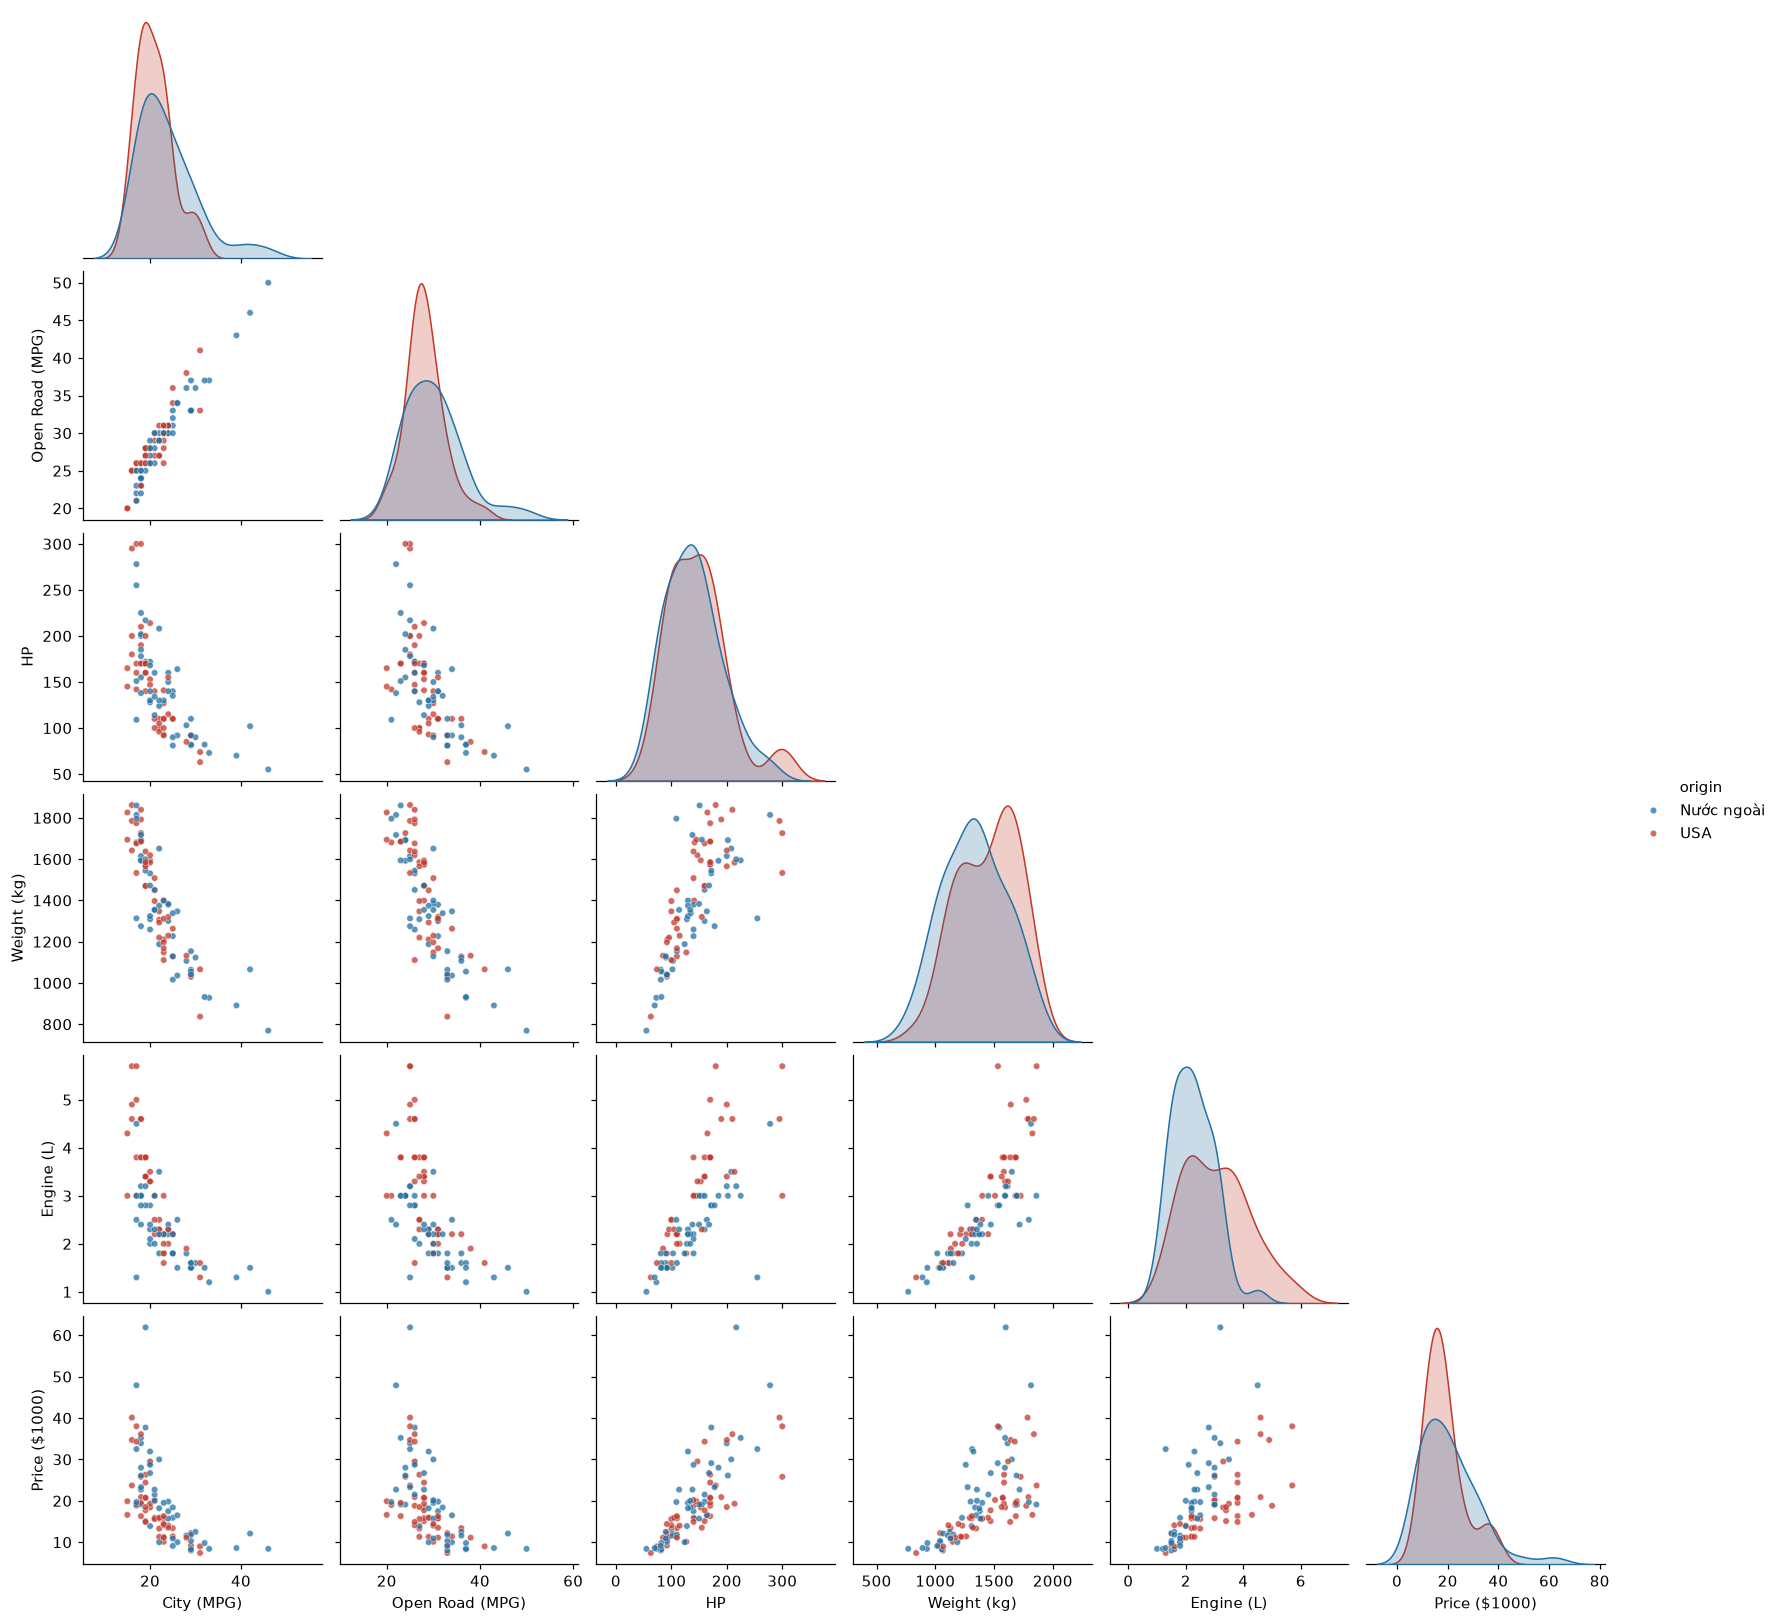

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_2_5_scatter.png


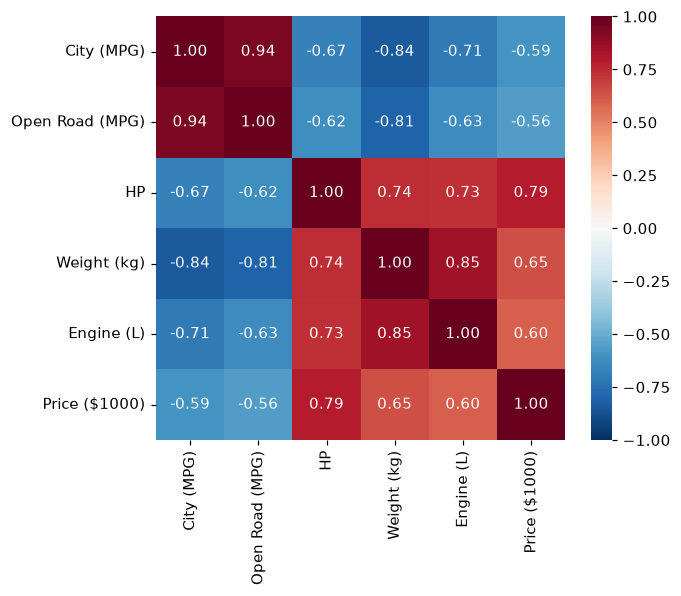

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_2_5_corr.png


In [6]:
cols = {"city": "City (MPG)", "open_road": "Open Road (MPG)", "hp": "HP",
        "weight": "Weight (kg)", "engine_size": "Engine (L)", "price": "Price ($1000)"}
g = sns.pairplot(d.rename(columns=cols), vars=list(cols.values()), hue="origin",
                 palette=COLOR, corner=True, plot_kws={"s": 18, "alpha": .75},
                 diag_kws={"common_norm": False})
g.figure.suptitle("Hình 2.5a — Ma trận scatterplot theo xuất xứ", y=1.01)
savefig(g.figure, "fig_2_5_scatter.png")

corr = d[list(cols)].rename(columns=cols).corr()
corr.to_csv(TAB / "tab_2_5_corr.csv")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Hình 2.5b — Ma trận tương quan")
savefig(fig, "fig_2_5_corr.png")

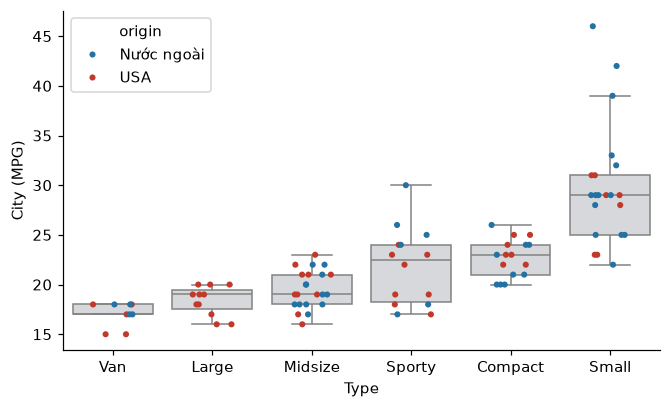

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_2_5_box_type.png


In [7]:
d["type_label"] = d["type"].map(TYPE_LABEL)
order = d.groupby("type_label")["city"].median().sort_values().index
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(d, x="type_label", y="city", order=order, color="#d5d8dc", ax=ax, showfliers=False)
sns.stripplot(d, x="type_label", y="city", order=order, hue="origin", palette=COLOR,
              ax=ax, size=4, jitter=.2)
ax.set(xlabel="Type", ylabel="City (MPG)", title="Hình 2.5c — City theo loại xe")
savefig(fig, "fig_2_5_box_type.png")

Preliminary outlier flags: cars far from the HP–City trend
(OLS log(City) ~ HP, |studentised residual| > 2).

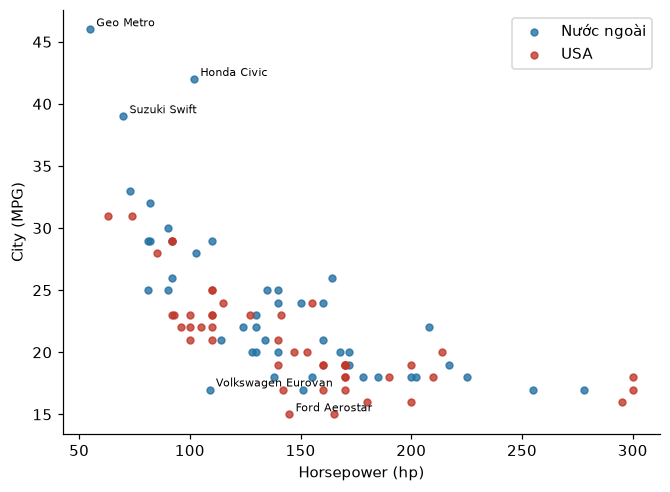

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_2_5_hp_city_flags.png
              name  hp  city  stud_resid
     Ford Aerostar 145    15       -2.41
         Geo Metro  55    46        3.24
       Honda Civic 102    42        3.59
      Suzuki Swift  70    39        2.36
Volkswagen Eurovan 109    17       -2.31


In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for o, sub in d.groupby("origin"):
    ax.scatter(sub["hp"], sub["city"], s=20, c=COLOR[o], label=o, alpha=.8)
ols_eda = sm.OLS(np.log(d["city"]), sm.add_constant(d["hp"])).fit()
stud = ols_eda.get_influence().resid_studentized_external
flag = d.loc[np.abs(stud) > 2, ["name", "hp", "city"]]
for _, r in flag.iterrows():
    ax.annotate(r["name"], (r["hp"], r["city"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set(xlabel="Horsepower (hp)", ylabel="City (MPG)", title="Hình 2.5d — HP và City, các điểm lạ sơ bộ")
ax.legend()
savefig(fig, "fig_2_5_hp_city_flags.png")
print(flag.assign(stud_resid=stud[np.abs(stud) > 2].round(2)).to_string(index=False))

## 3.2–3.3 Đa cộng tuyến (VIF), City vs log(City), OLS baseline

In [9]:
X = d[["hp", "weight", "engine_size"]]
vif = pd.Series([variance_inflation_factor(sm.add_constant(X).values, i + 1) for i in range(X.shape[1])],
                index=X.columns, name="VIF")
X2 = d[["hp", "weight", "usa"]]
vif_m4 = pd.Series([variance_inflation_factor(sm.add_constant(X2).values, i + 1) for i in range(X2.shape[1])],
                   index=X2.columns, name="VIF (M4)")
vif_tab = pd.concat([vif, vif_m4], axis=1)
vif_tab.to_csv(TAB / "tab_3_2_vif.csv")
print(vif_tab.round(2).to_string())

              VIF  VIF (M4)
hp           2.42      2.24
weight       3.93      2.34
engine_size  3.84       NaN
usa           NaN      1.07


 response    R2  loglik_city_scale  AIC_city_scale
     City 0.452           -263.998         533.996
log(City) 0.506           -246.013         498.027


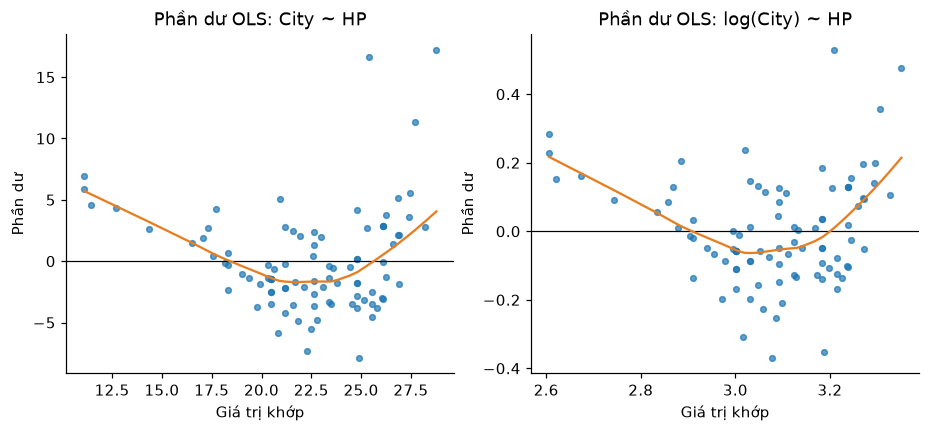

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_3_3_response_scale.png


In [10]:
# Compare response scales on the City scale (log-likelihood includes the Jacobian).
rows = []
for label, yy, jac in [("City", d["city"], 0.0),
                       ("log(City)", np.log(d["city"]), -np.log(d["city"]).sum())]:
    m = sm.OLS(yy, sm.add_constant(d["hp"])).fit()
    rows.append({"response": label, "R2": m.rsquared, "loglik_city_scale": m.llf + jac,
                 "AIC_city_scale": -2 * (m.llf + jac) + 2 * 3})
resp_tab = pd.DataFrame(rows)
resp_tab.to_csv(TAB / "tab_3_3_response_scale.csv", index=False)
print(resp_tab.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, yy) in zip(axes, [("City", d["city"]), ("log(City)", np.log(d["city"]))]):
    m = sm.OLS(yy, sm.add_constant(d["hp"])).fit()
    ax.scatter(m.fittedvalues, m.resid, s=14, alpha=.7)
    ax.axhline(0, c="k", lw=.8)
    sm_lowess = sm.nonparametric.lowess(m.resid, m.fittedvalues)
    ax.plot(sm_lowess[:, 0], sm_lowess[:, 1], c="#e67e22")
    ax.set(title=f"Phần dư OLS: {label} ~ HP", xlabel="Giá trị khớp", ylabel="Phần dư")
fig.suptitle("Hình 3.3 — So sánh City và log(City)")
savefig(fig, "fig_3_3_response_scale.png")

In [11]:
# OLS baseline for every candidate model, on the same standardised scale as the Bayesian models.
sc = Scaler(d)
ols_rows = []
for name, terms in MODEL_TERMS.items():
    Xm = sm.add_constant(design(d, sc, terms))
    m = sm.OLS(sc.y(d["city"]), Xm).fit()
    ci = m.conf_int()
    for i, t in enumerate(["b0"] + terms):
        ols_rows.append({"model": name, "term": t, "coef": m.params[i], "se": m.bse[i],
                         "ci_low": ci[i, 0], "ci_high": ci[i, 1]})
ols_tab = pd.DataFrame(ols_rows)
ols_tab.to_csv(TAB / "tab_3_1_ols.csv", index=False)
print(ols_tab.round(3).to_string(index=False))

save_results(scaler={"hp_mu": sc.hp_mu, "hp_sd": sc.hp_sd, "w_mu": sc.w_mu, "w_sd": sc.w_sd,
                     "logy_mu": sc.y_mu, "logy_sd": sc.y_sd},
             vif=vif_tab.round(3).to_dict(),
             response_scale=resp_tab.round(3).to_dict("records"))

model   term   coef    se  ci_low  ci_high
   M1     b0  0.000 0.073  -0.146    0.146
   M1     hp -0.711 0.074  -0.858   -0.565
   M2     b0  0.211 0.101   0.009    0.412
   M2     hp -0.696 0.071  -0.838   -0.555
   M2    usa -0.408 0.141  -0.689   -0.127
   M3     b0  0.198 0.100   0.000    0.397
   M3     hp -0.860 0.105  -1.068   -0.653
   M3    usa -0.405 0.139  -0.681   -0.129
   M3 hp_usa  0.296 0.140   0.017    0.574
   M4     b0  0.084 0.070  -0.055    0.223
   M4     hp -0.145 0.072  -0.288   -0.002
   M4 weight -0.759 0.074  -0.905   -0.613
   M4    usa -0.163 0.099  -0.360    0.033


# 02_models — Đặc tả M1–M5, prior predictive check, phân tích độ nhạy (Chương 3)
Owner: Nguyễn Thị Bích Ngọc. Models are defined in `common.build_model`; response = standardised
log(City), predictors HP and Weight standardised, USA kept as 0/1.

M3 (full spec, section 3.5), on the standardised scale:

y_i ~ N(mu_i, sigma^2),  mu_i = b0 + b1 HP_i + b2 USA_i + b3 HP_i USA_i,
b_j ~ N(0, 2.5^2),  sigma ~ Half-Normal(1)

In [12]:
from common import *  # noqa: F401,F403
import arviz as az
import pymc as pm

d = load_clean()
sc = Scaler(d)
for name, terms in MODEL_TERMS.items():
    print(name, MODEL_FORMULA[name], "->", terms)

M1 City ~ HP -> ['hp']
M2 City ~ HP + USA -> ['hp', 'usa']
M3 City ~ HP + USA + HP×USA -> ['hp', 'usa', 'hp_usa']
M4 City ~ HP + Weight + USA -> ['hp', 'weight', 'usa']


## 3.6 Prior predictive check
Data simulated from the prior should stay in a plausible range: City > 0 (always true on
the log scale) and City ≤ 80 MPG. Checked for M3 under the three prior sets.

In [13]:
ppc_rows, prior_draws = [], {}
for prior in PRIOR_SD:
    with build_model(d, sc, MODEL_TERMS["M3"], prior=prior):
        pp = pm.sample_prior_predictive(draws=1000, random_seed=SEED)
    mpg = sc.to_mpg(pp.prior_predictive["y"].values.ravel())
    prior_draws[prior] = mpg
    ppc_rows.append({"prior": prior, "coef_sd": PRIOR_SD[prior],
                     "share_le_80mpg": np.mean(mpg <= 80),
                     "share_5_to_80mpg": np.mean((mpg >= 5) & (mpg <= 80)),
                     "median_mpg": np.median(mpg),
                     "q01": np.quantile(mpg, .01), "q99": np.quantile(mpg, .99)})
ppc_tab = pd.DataFrame(ppc_rows)
ppc_tab.to_csv(TAB / "tab_3_6_prior_predictive.csv", index=False)
print(ppc_tab.round(3).to_string(index=False))

Sampling: [b, b0, sigma, y]


Sampling: [b, b0, sigma, y]


Sampling: [b, b0, sigma, y]


prior  coef_sd  share_le_80mpg  share_5_to_80mpg  median_mpg   q01          q99
 flat    100.0           0.533             0.034       5.364 0.000 2.119721e+45
 weak      2.5           0.921             0.862      21.011 1.728 2.895530e+02
tight      0.5           0.999             0.999      21.627 9.738 4.873900e+01


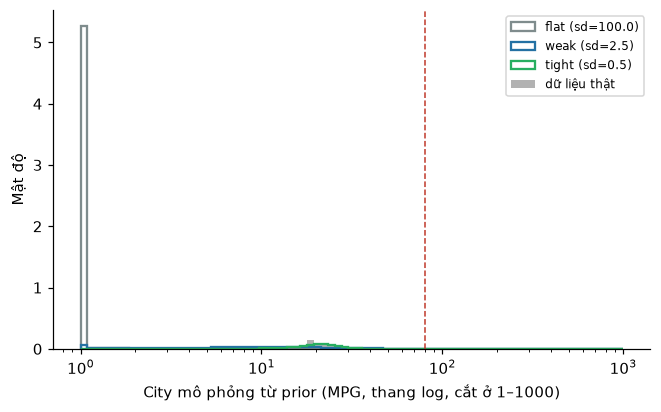

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_3_6_prior_predictive.png


In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.logspace(0, 3, 80)
for prior, c in zip(PRIOR_SD, ["#7f8c8d", "#2471a3", "#27ae60"]):
    ax.hist(np.clip(prior_draws[prior], 1, 1000), bins=bins, histtype="step", lw=1.5,
            density=True, color=c, label=f"{prior} (sd={PRIOR_SD[prior]})")
ax.hist(d["city"], bins=bins, color="k", alpha=.3, density=True, label="dữ liệu thật")
ax.axvline(80, ls="--", c="#c0392b", lw=1)
ax.set(xscale="log", xlabel="City mô phỏng từ prior (MPG, thang log, cắt ở 1–1000)",
       ylabel="Mật độ", title="Hình 3.6 — Prior predictive check cho M3")
ax.legend(fontsize=8)
savefig(fig, "fig_3_6_prior_predictive.png")

## 3.7 Phân tích độ nhạy: M3 under flat / weak / tight priors

In [15]:
sens = {}
for prior in PRIOR_SD:
    with build_model(d, sc, MODEL_TERMS["M3"], prior=prior):
        sens[prior] = pm.sample(**SAMPLE_KW)
    sens[prior].to_netcdf(IDATA / f"idata_M3_prior_{prior}.nc")

rows = []
for prior, idata in sens.items():
    s = az.summary(idata, var_names=["b0", "b", "sigma"], hdi_prob=.95)
    s.insert(0, "prior", prior)
    rows.append(s)
sens_tab = pd.concat(rows)
sens_tab.to_csv(TAB / "tab_3_7_sensitivity.csv")
print(sens_tab[["prior", "mean", "sd", "hdi_2.5%", "hdi_97.5%", "r_hat"]].to_string())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [b0, b, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 35 seconds.


Initializing NUTS using jitter+adapt_diag...


...

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [b0, b, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 33 seconds.


           prior   mean     sd  hdi_2.5%  hdi_97.5%  r_hat
b0          flat  0.200  0.101     0.008      0.405    1.0
b[hp]       flat -0.862  0.107    -1.071     -0.651    1.0
b[usa]      flat -0.406  0.142    -0.692     -0.133    1.0
b[hp_usa]   flat  0.297  0.143     0.005      0.570    1.0
sigma       flat  0.676  0.051     0.581      0.779    1.0
b0          weak  0.196  0.101     0.006      0.399    1.0
b[hp]       weak -0.859  0.107    -1.069     -0.651    1.0
b[usa]      weak -0.402  0.139    -0.686     -0.142    1.0
b[hp_usa]   weak  0.294  0.144     0.026      0.590    1.0
sigma       weak  0.675  0.052     0.580      0.781    1.0
b0         tight  0.181  0.097    -0.002      0.376    1.0
b[hp]      tight -0.814  0.102    -1.014     -0.611    1.0
b[usa]     tight -0.373  0.133    -0.643     -0.122    1.0
b[hp_usa]  tight  0.239  0.137    -0.038      0.503    1.0
sigma      tight  0.675  0.052     0.578      0.779    1.0


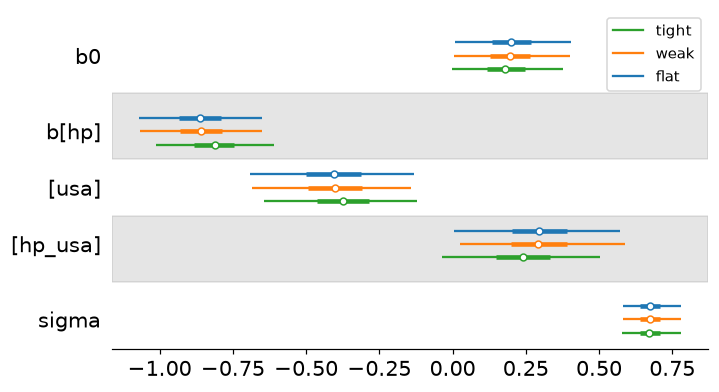

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_3_7_sensitivity.png
max |mean shift| / sd vs weak: {'flat': 0.03960396039603964, 'weak': 0.0, 'tight': 0.4205607476635518}


In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
az.plot_forest(list(sens.values()), model_names=list(sens), var_names=["b0", "b", "sigma"],
               combined=True, hdi_prob=.95, ax=ax)
ax.set_title("Hình 3.7 — Hậu nghiệm M3 dưới 3 bộ prior (HDI 95%)")
savefig(fig, "fig_3_7_sensitivity.png")

# Largest shift of a posterior mean relative to the weak prior, in posterior sds.
weak = sens_tab[sens_tab.prior == "weak"]
shift = {p: float((np.abs(sens_tab[sens_tab.prior == p]["mean"] - weak["mean"]) / weak["sd"]).max())
         for p in PRIOR_SD}
print("max |mean shift| / sd vs weak:", shift)
save_results(prior_predictive=ppc_tab.round(4).to_dict("records"), sensitivity_max_shift_sd=shift)

# 03_sampling — NUTS cho M1–M5, chẩn đoán hội tụ, Metropolis–Hastings tự cài (Chương 4)
Owner: Nguyễn Thu Ngân. Output: `outputs/idata/idata_M*.nc`, posterior tables (4.4), diagnostics (4.3).

In [17]:
from common import *  # noqa: F401,F403
import arviz as az
import pymc as pm

d = load_clean()
sc = Scaler(d)
VARS = ["b0", "b", "sigma"]

## 4.2 NUTS for M1–M4 (4 chains × 2000 draws, 1000 warm-up, seed 2026)

In [18]:
idatas = {}
for name, terms in MODEL_TERMS.items():
    with build_model(d, sc, terms):
        idatas[name] = pm.sample(**SAMPLE_KW)
        pm.sample_posterior_predictive(idatas[name], extend_inferencedata=True, random_seed=SEED,
                                       progressbar=False)
    idatas[name].to_netcdf(IDATA / f"idata_{name}.nc")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [b0, b, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 24 seconds.


Sampling: [y]


...

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [b0, b, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 37 seconds.


Sampling: [y]


M5 = the best of M1–M4 by PSIS-LOO, refitted with a Student-t likelihood
(robust to outliers). The full comparison is in 05_evaluation.

In [19]:
loo_rank = az.compare({k: idatas[k] for k in MODEL_TERMS}, ic="loo")
m5_base = loo_rank.index[0]
print(loo_rank[["rank", "elpd_loo", "se", "elpd_diff", "dse"]].round(2))
print("M5 base:", m5_base)
save_results(m5_base=m5_base)

with build_model(d, sc, MODEL_TERMS[m5_base], likelihood="student"):
    idatas["M5"] = pm.sample(**SAMPLE_KW)
    pm.sample_posterior_predictive(idatas["M5"], extend_inferencedata=True, random_seed=SEED,
                                   progressbar=False)
idatas["M5"].to_netcdf(IDATA / "idata_M5.nc")

Initializing NUTS using jitter+adapt_diag...


    rank  elpd_loo     se  elpd_diff   dse
M4     0    -64.24  10.71       0.00  0.00
M3     1    -98.17   8.23      33.94  8.45
M2     2    -99.34   8.76      35.11  8.27
M1     3   -102.43   8.94      38.19  7.76
M5 base: M4


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [b0, b, sigma, nu]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 107 seconds.


Sampling: [y]


PosixPath('/Users/huybq/Documents/work stuff/special-topic/final-project/outputs/idata/idata_M5.nc')

## 4.3 Chẩn đoán hội tụ: R-hat < 1.01, ESS bulk/tail > 400, 0 divergence

In [20]:
diag_rows = []
for name, idata in idatas.items():
    var_names = VARS + (["nu"] if name == "M5" else [])
    s = az.summary(idata, var_names=var_names)
    div = int(idata.sample_stats["diverging"].sum())
    diag_rows.append({"model": name, "max_r_hat": s["r_hat"].max(),
                      "min_ess_bulk": s["ess_bulk"].min(), "min_ess_tail": s["ess_tail"].min(),
                      "divergences": div,
                      "pass": bool(s["r_hat"].max() < 1.01 and s["ess_bulk"].min() > 400
                                   and s["ess_tail"].min() > 400 and div == 0)})
diag = pd.DataFrame(diag_rows)
diag.to_csv(TAB / "tab_4_3_diagnostics.csv", index=False)
print(diag.to_string(index=False))
assert diag["pass"].all(), "a chain failed the convergence gate — do not interpret coefficients"

model  max_r_hat  min_ess_bulk  min_ess_tail  divergences  pass
   M1        1.0       10830.0        5460.0            0  True
   M2        1.0        6013.0        5295.0            0  True
   M3        1.0        5618.0        5197.0            0  True
   M4        1.0        5116.0        5091.0            0  True
   M5        1.0        4626.0        4763.0            0  True


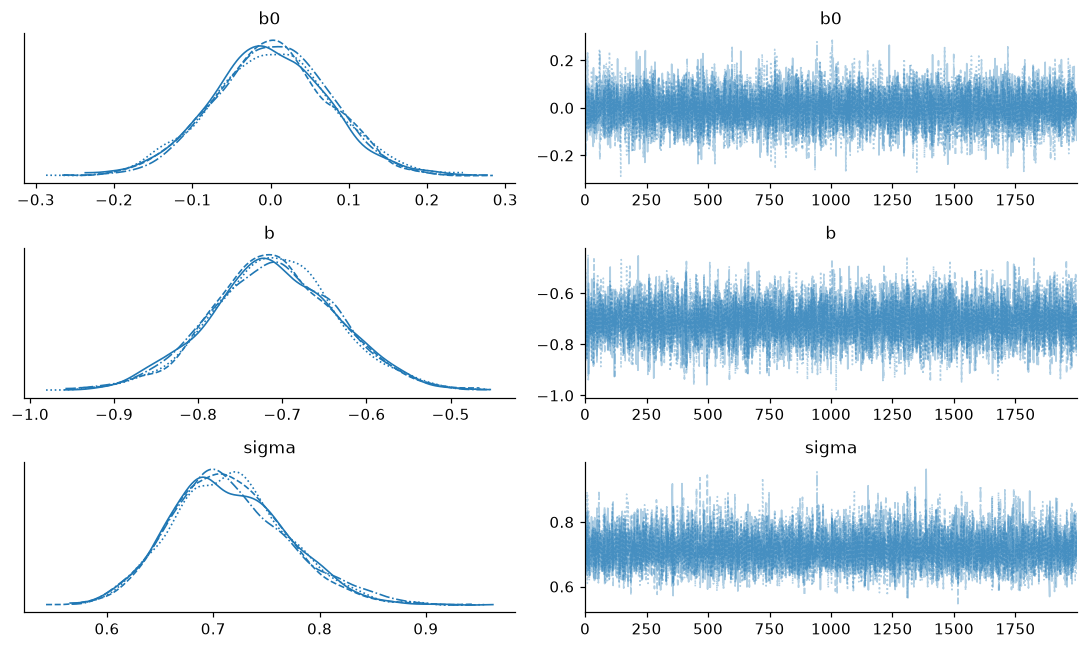

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_trace_M1.png


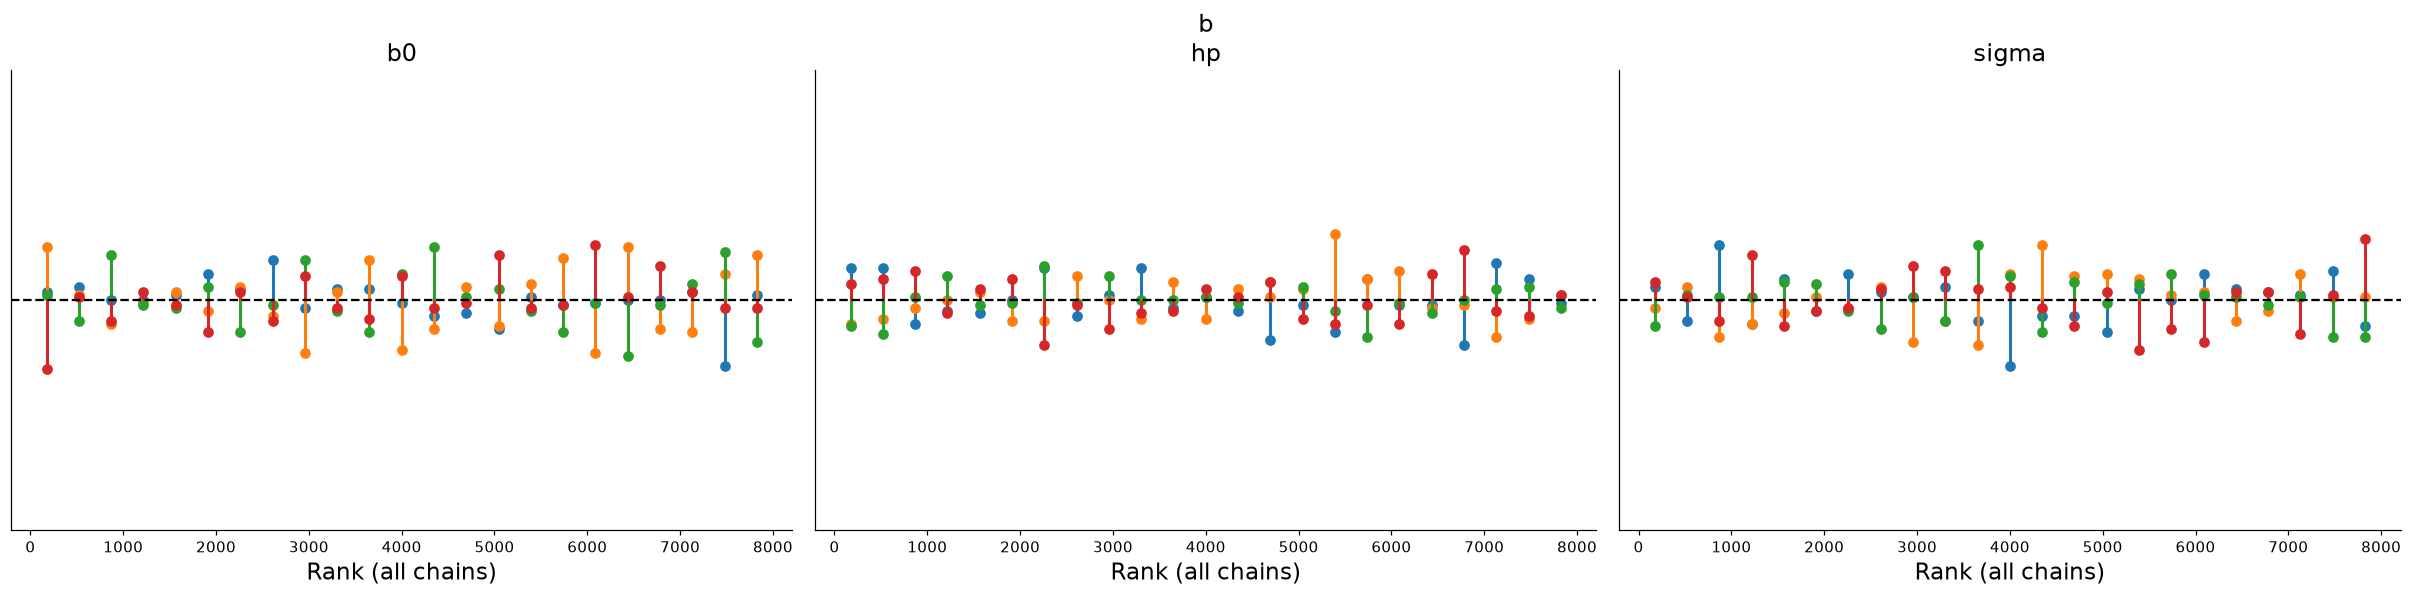

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_rank_M1.png


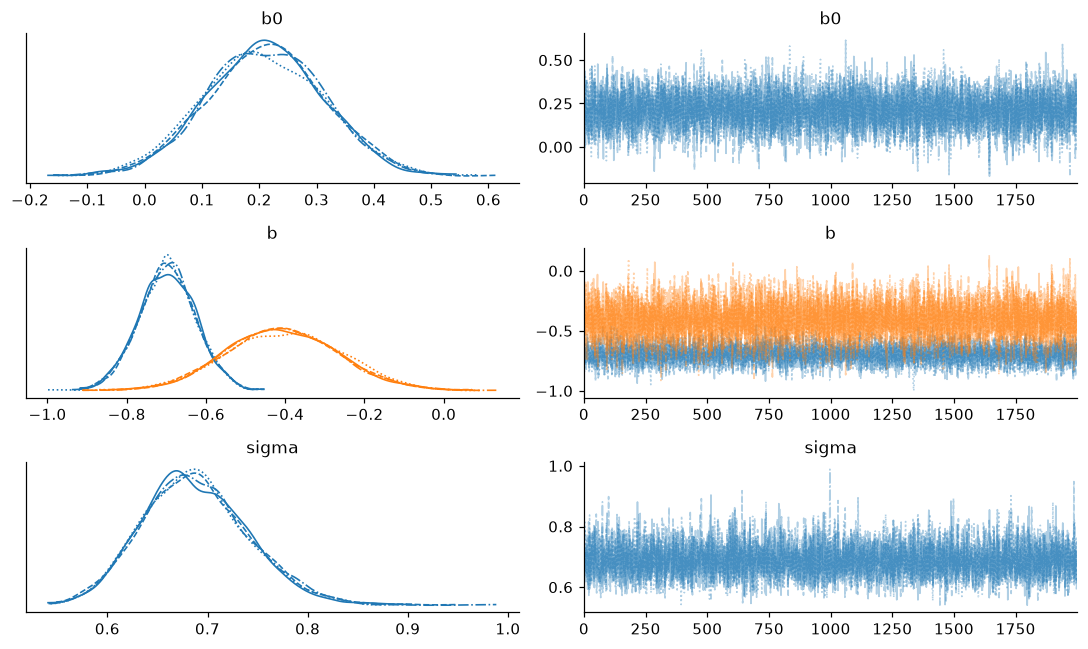

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_trace_M2.png


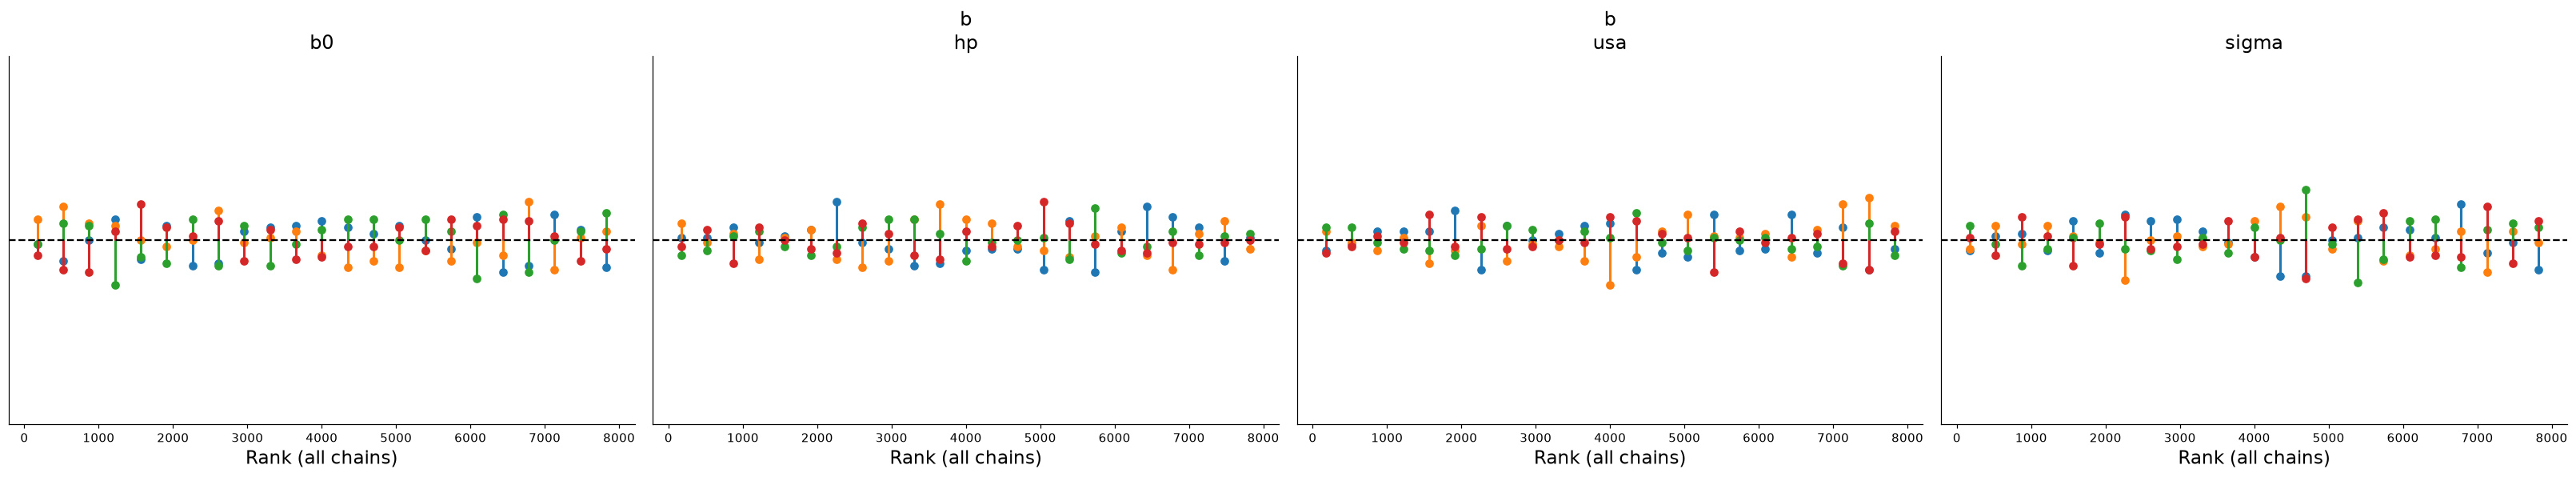

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_rank_M2.png


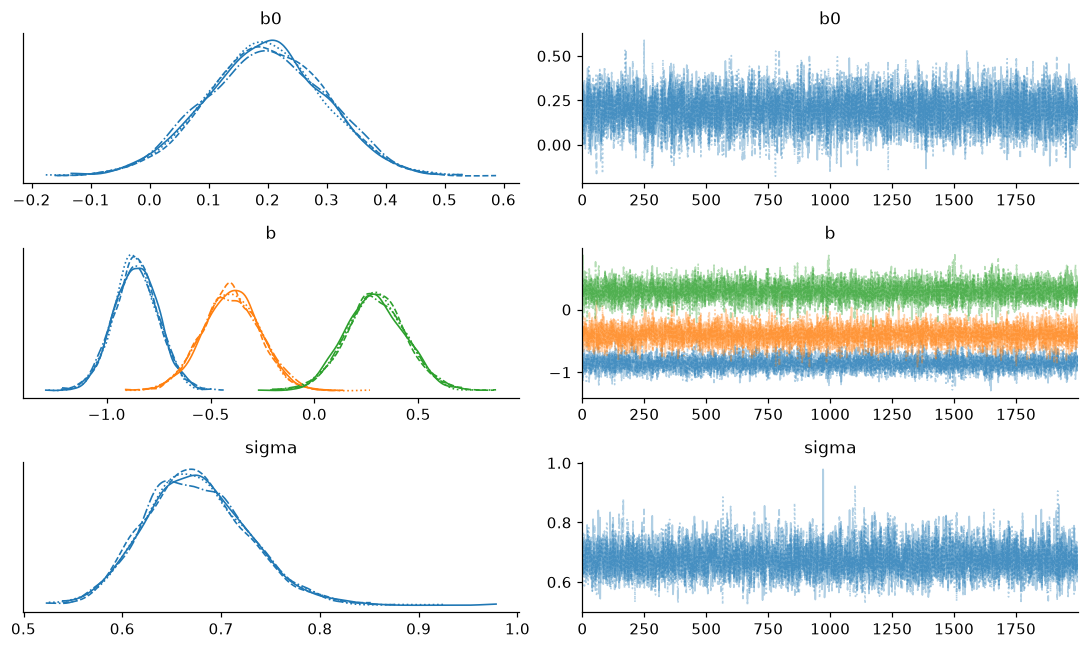

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_trace_M3.png


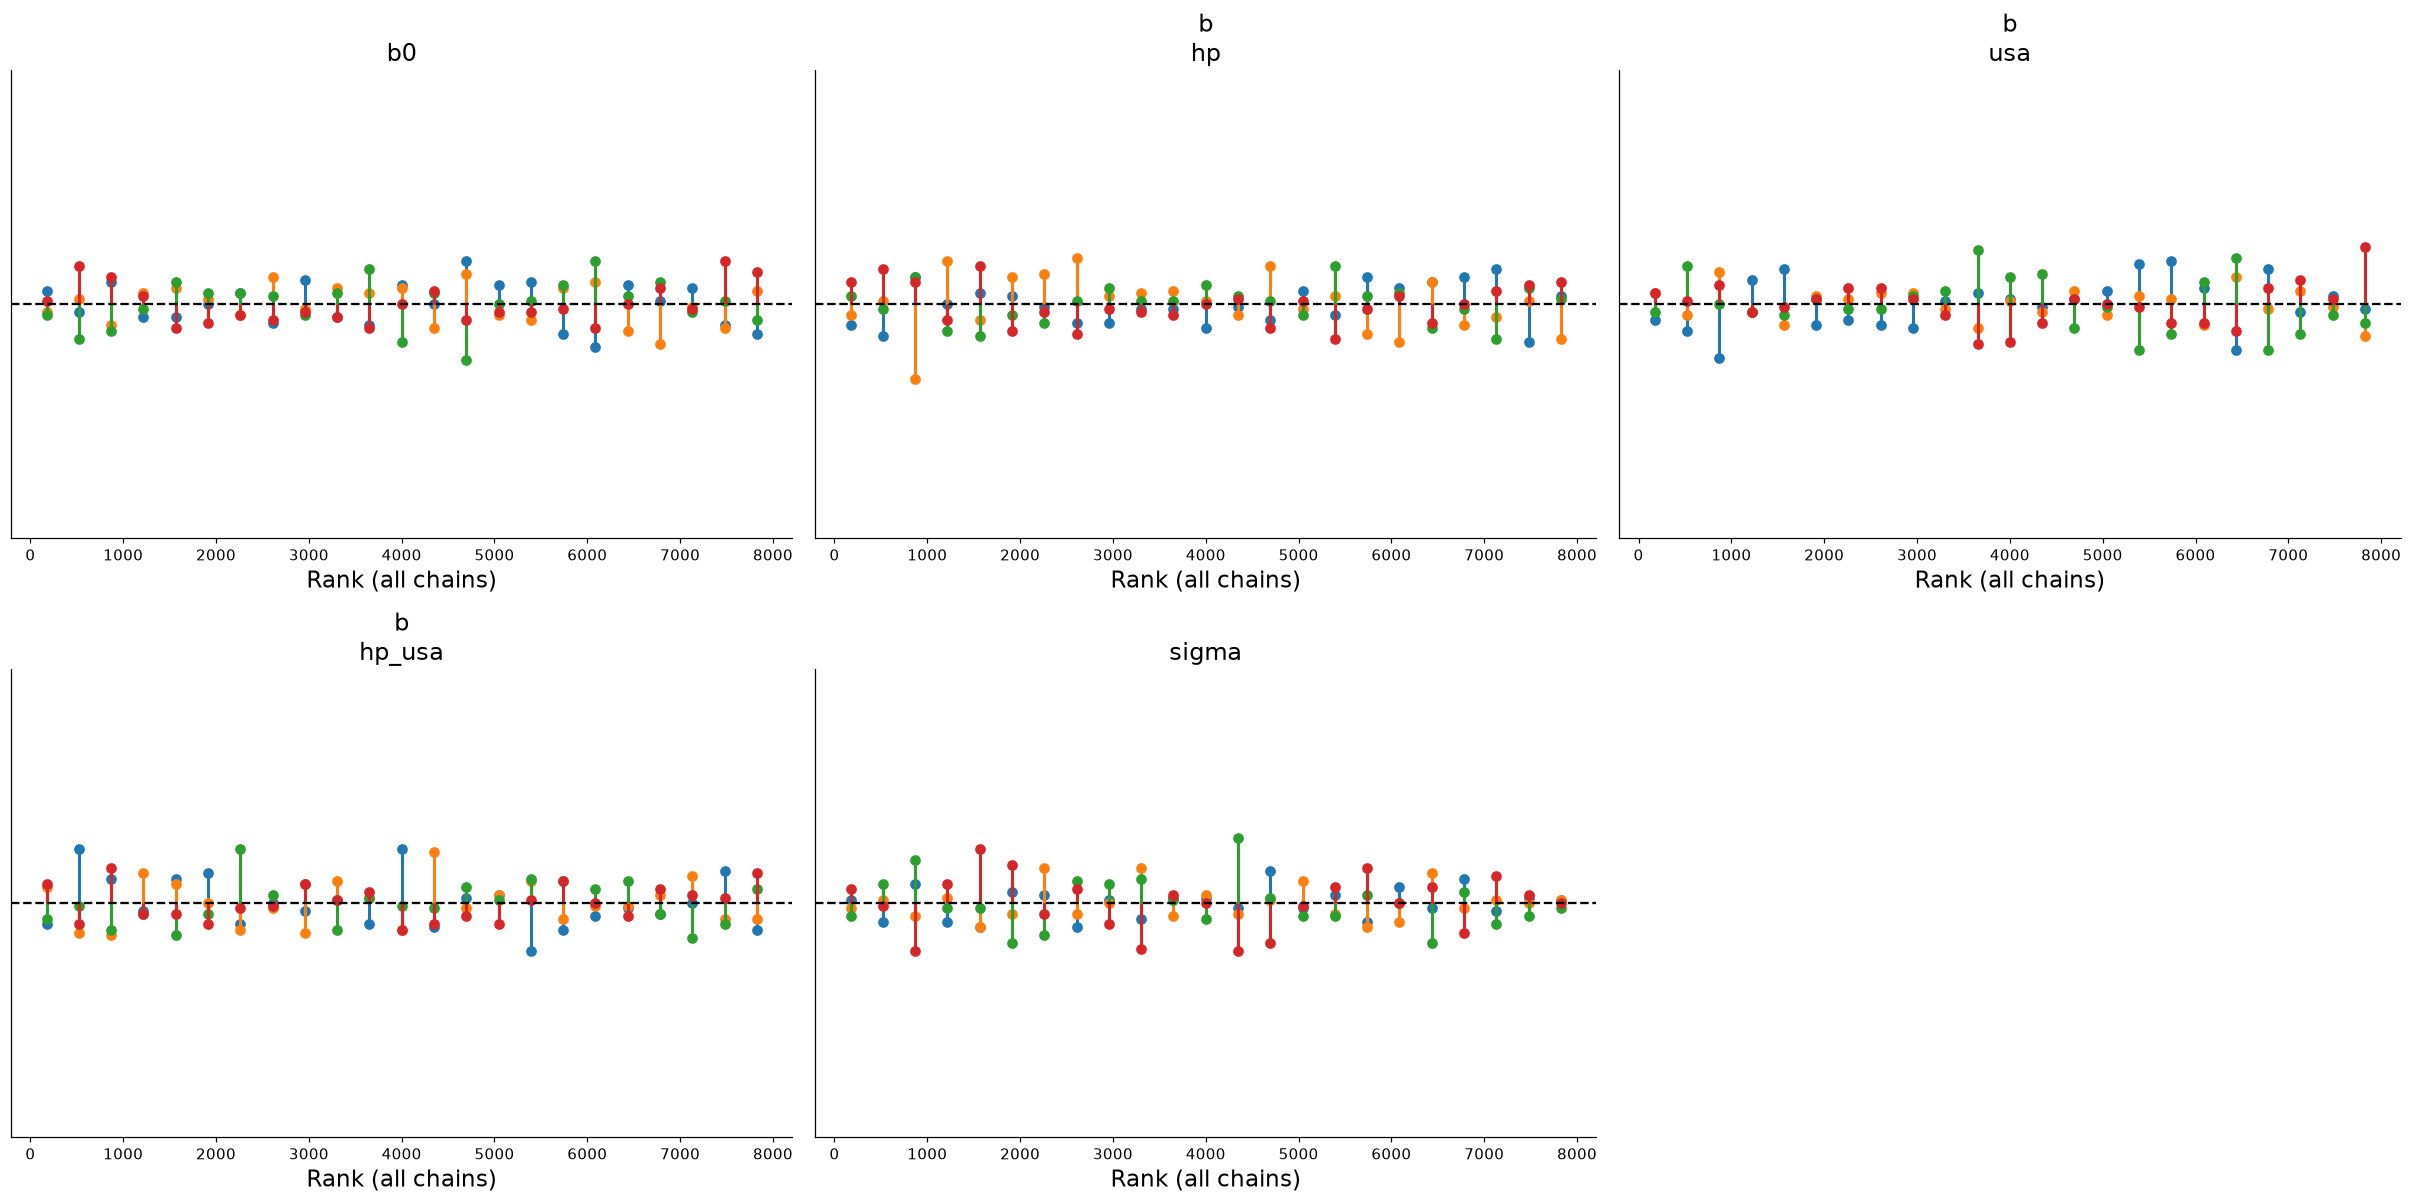

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_rank_M3.png


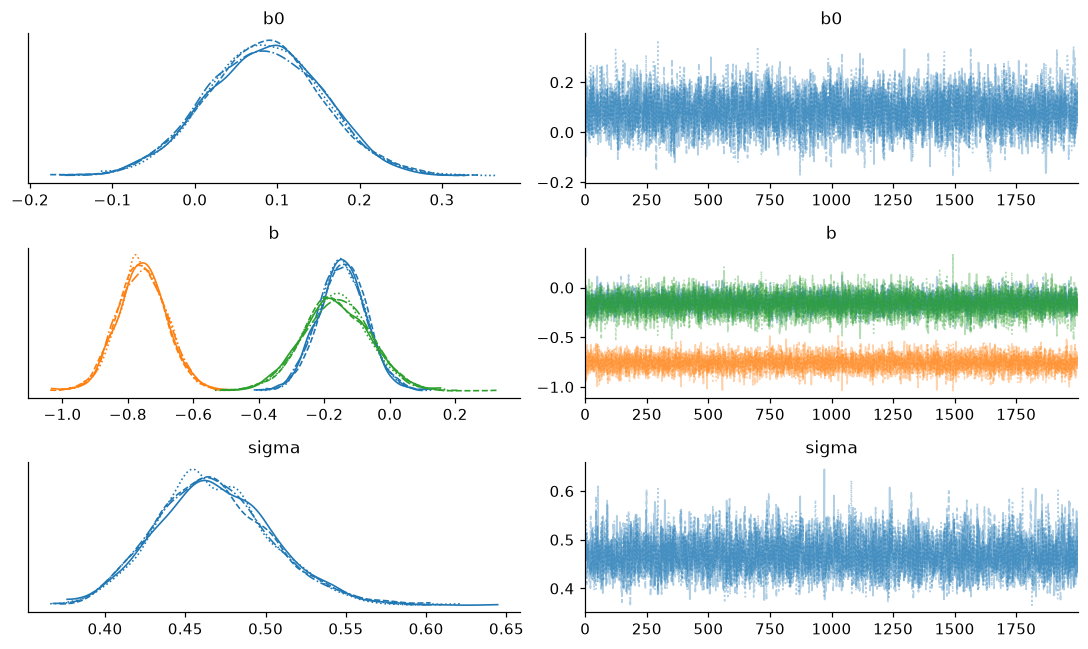

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_trace_M4.png


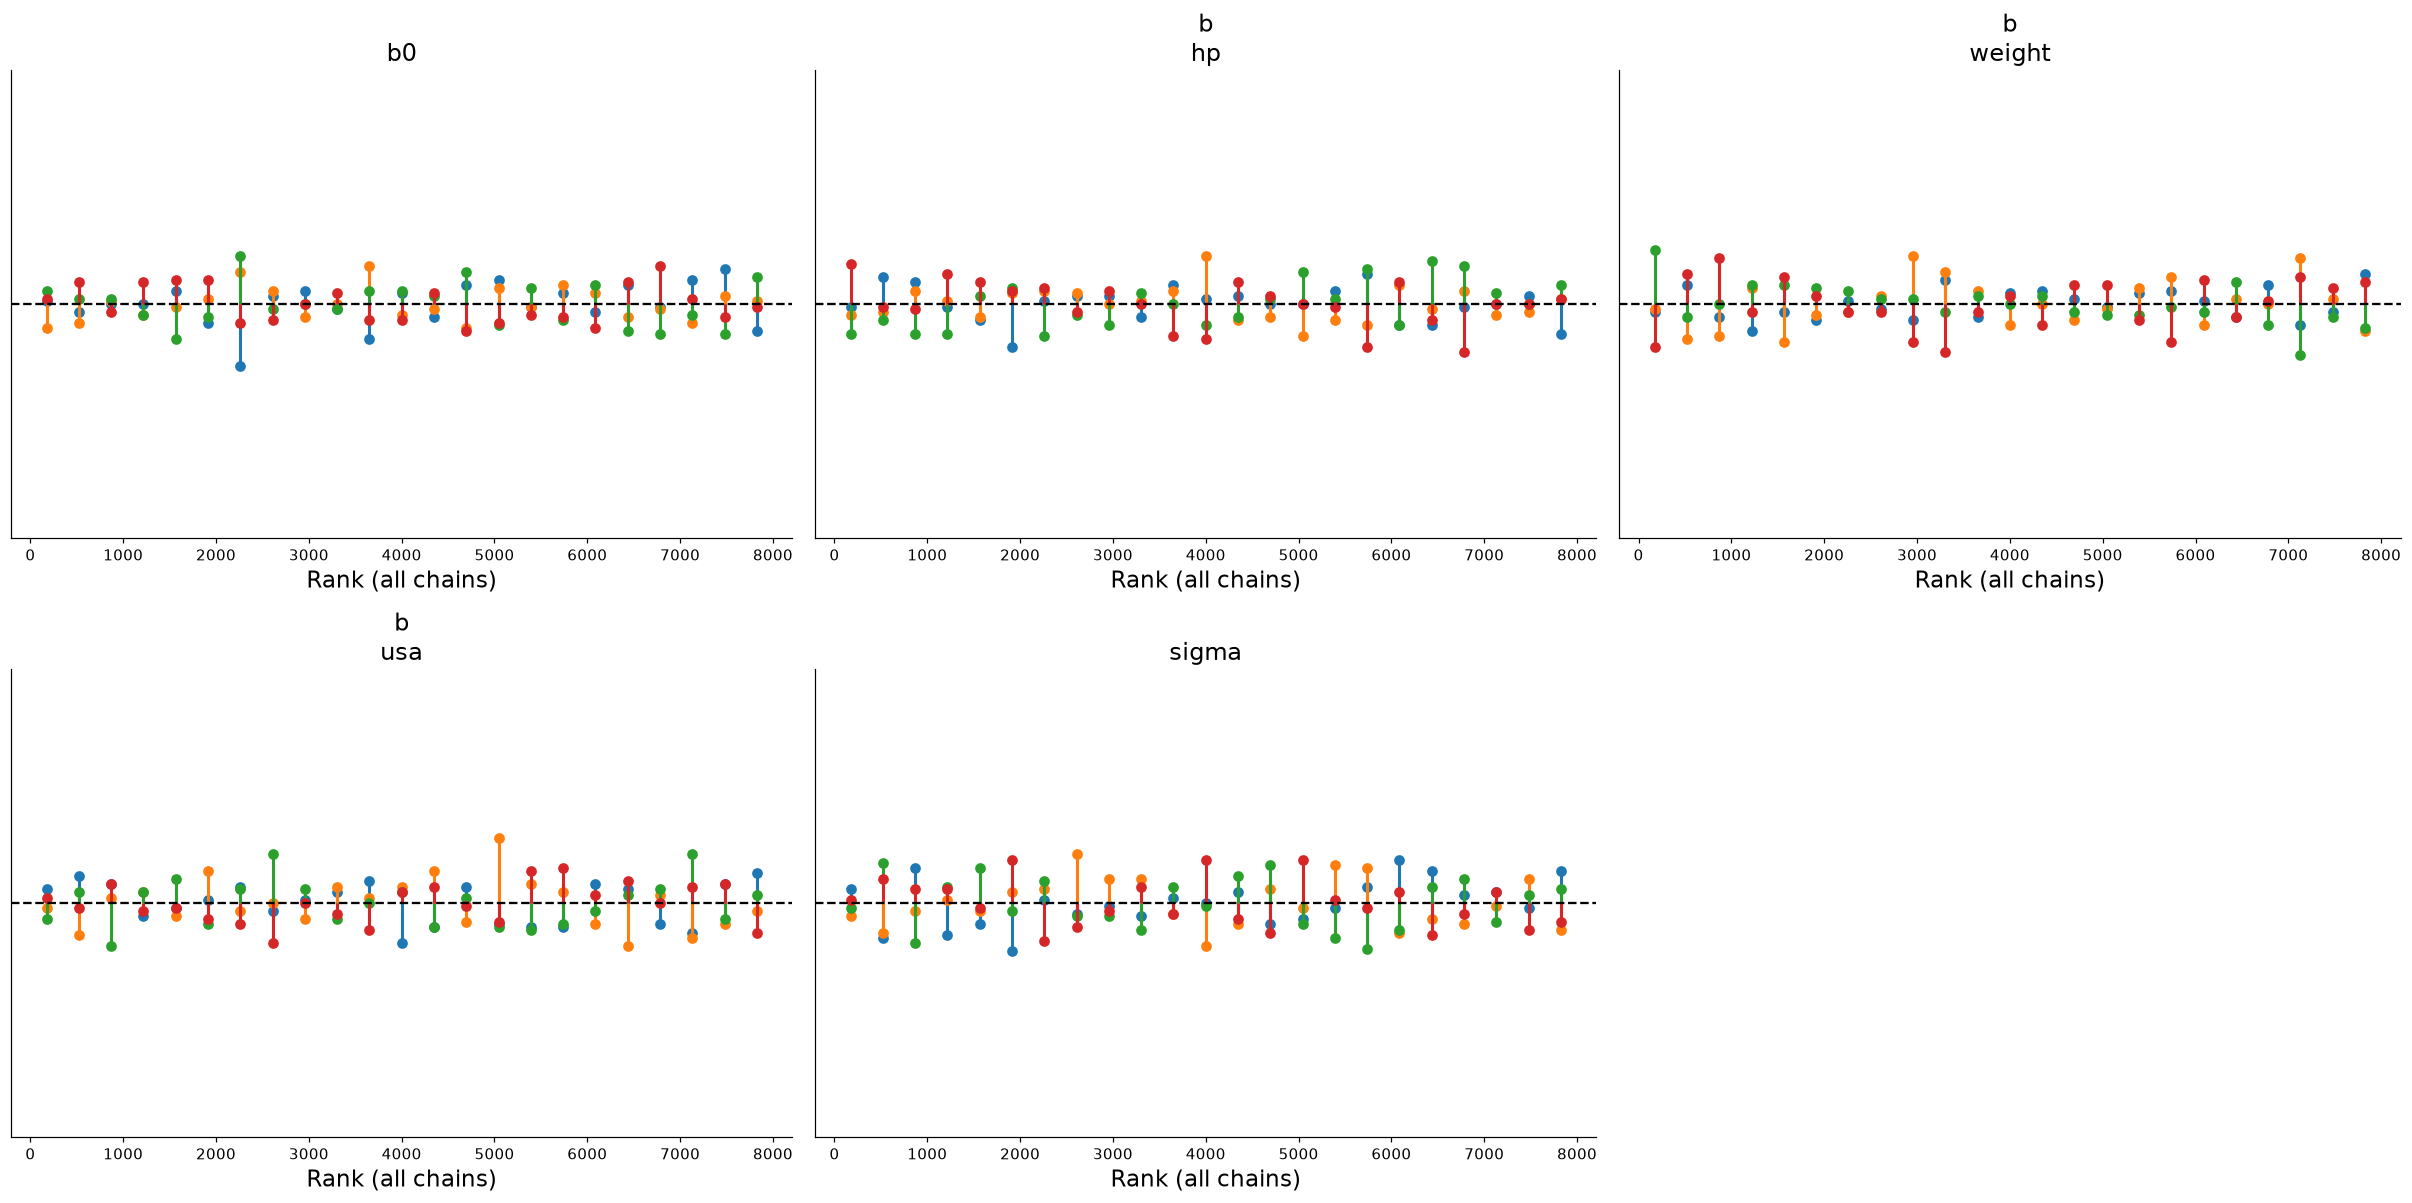

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_rank_M4.png


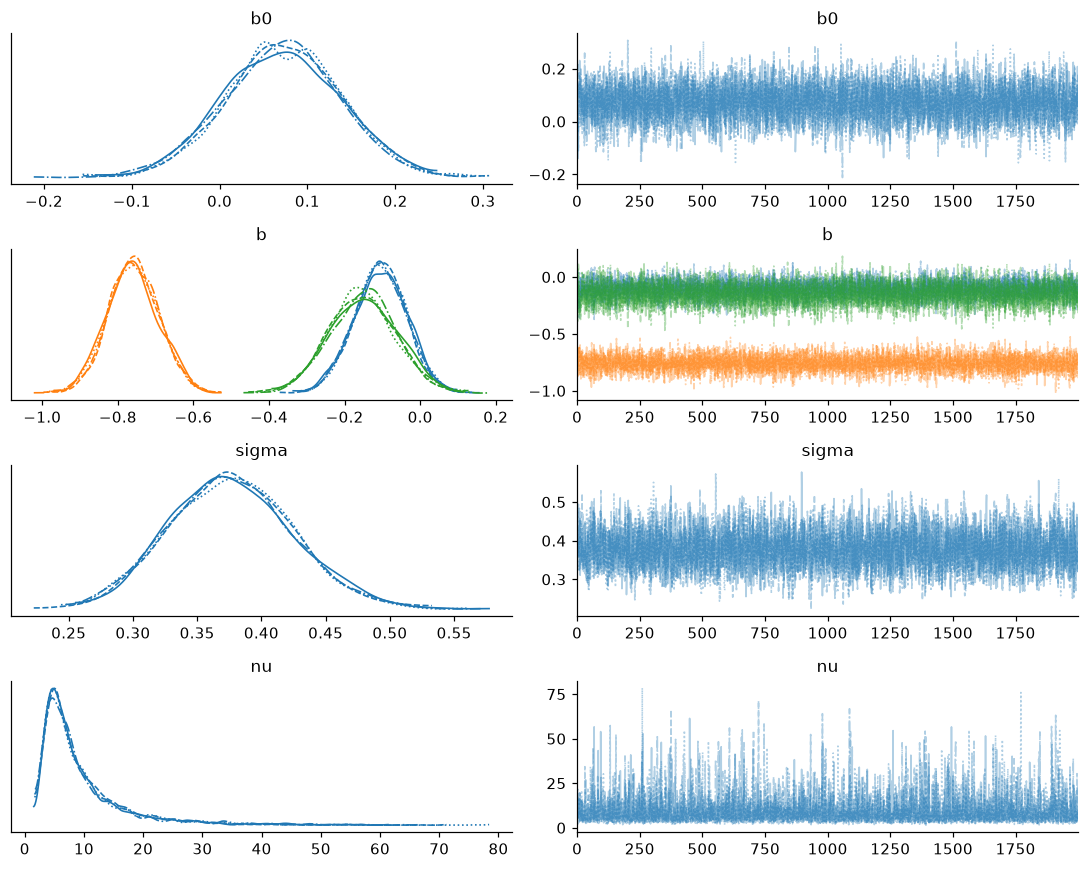

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_trace_M5.png


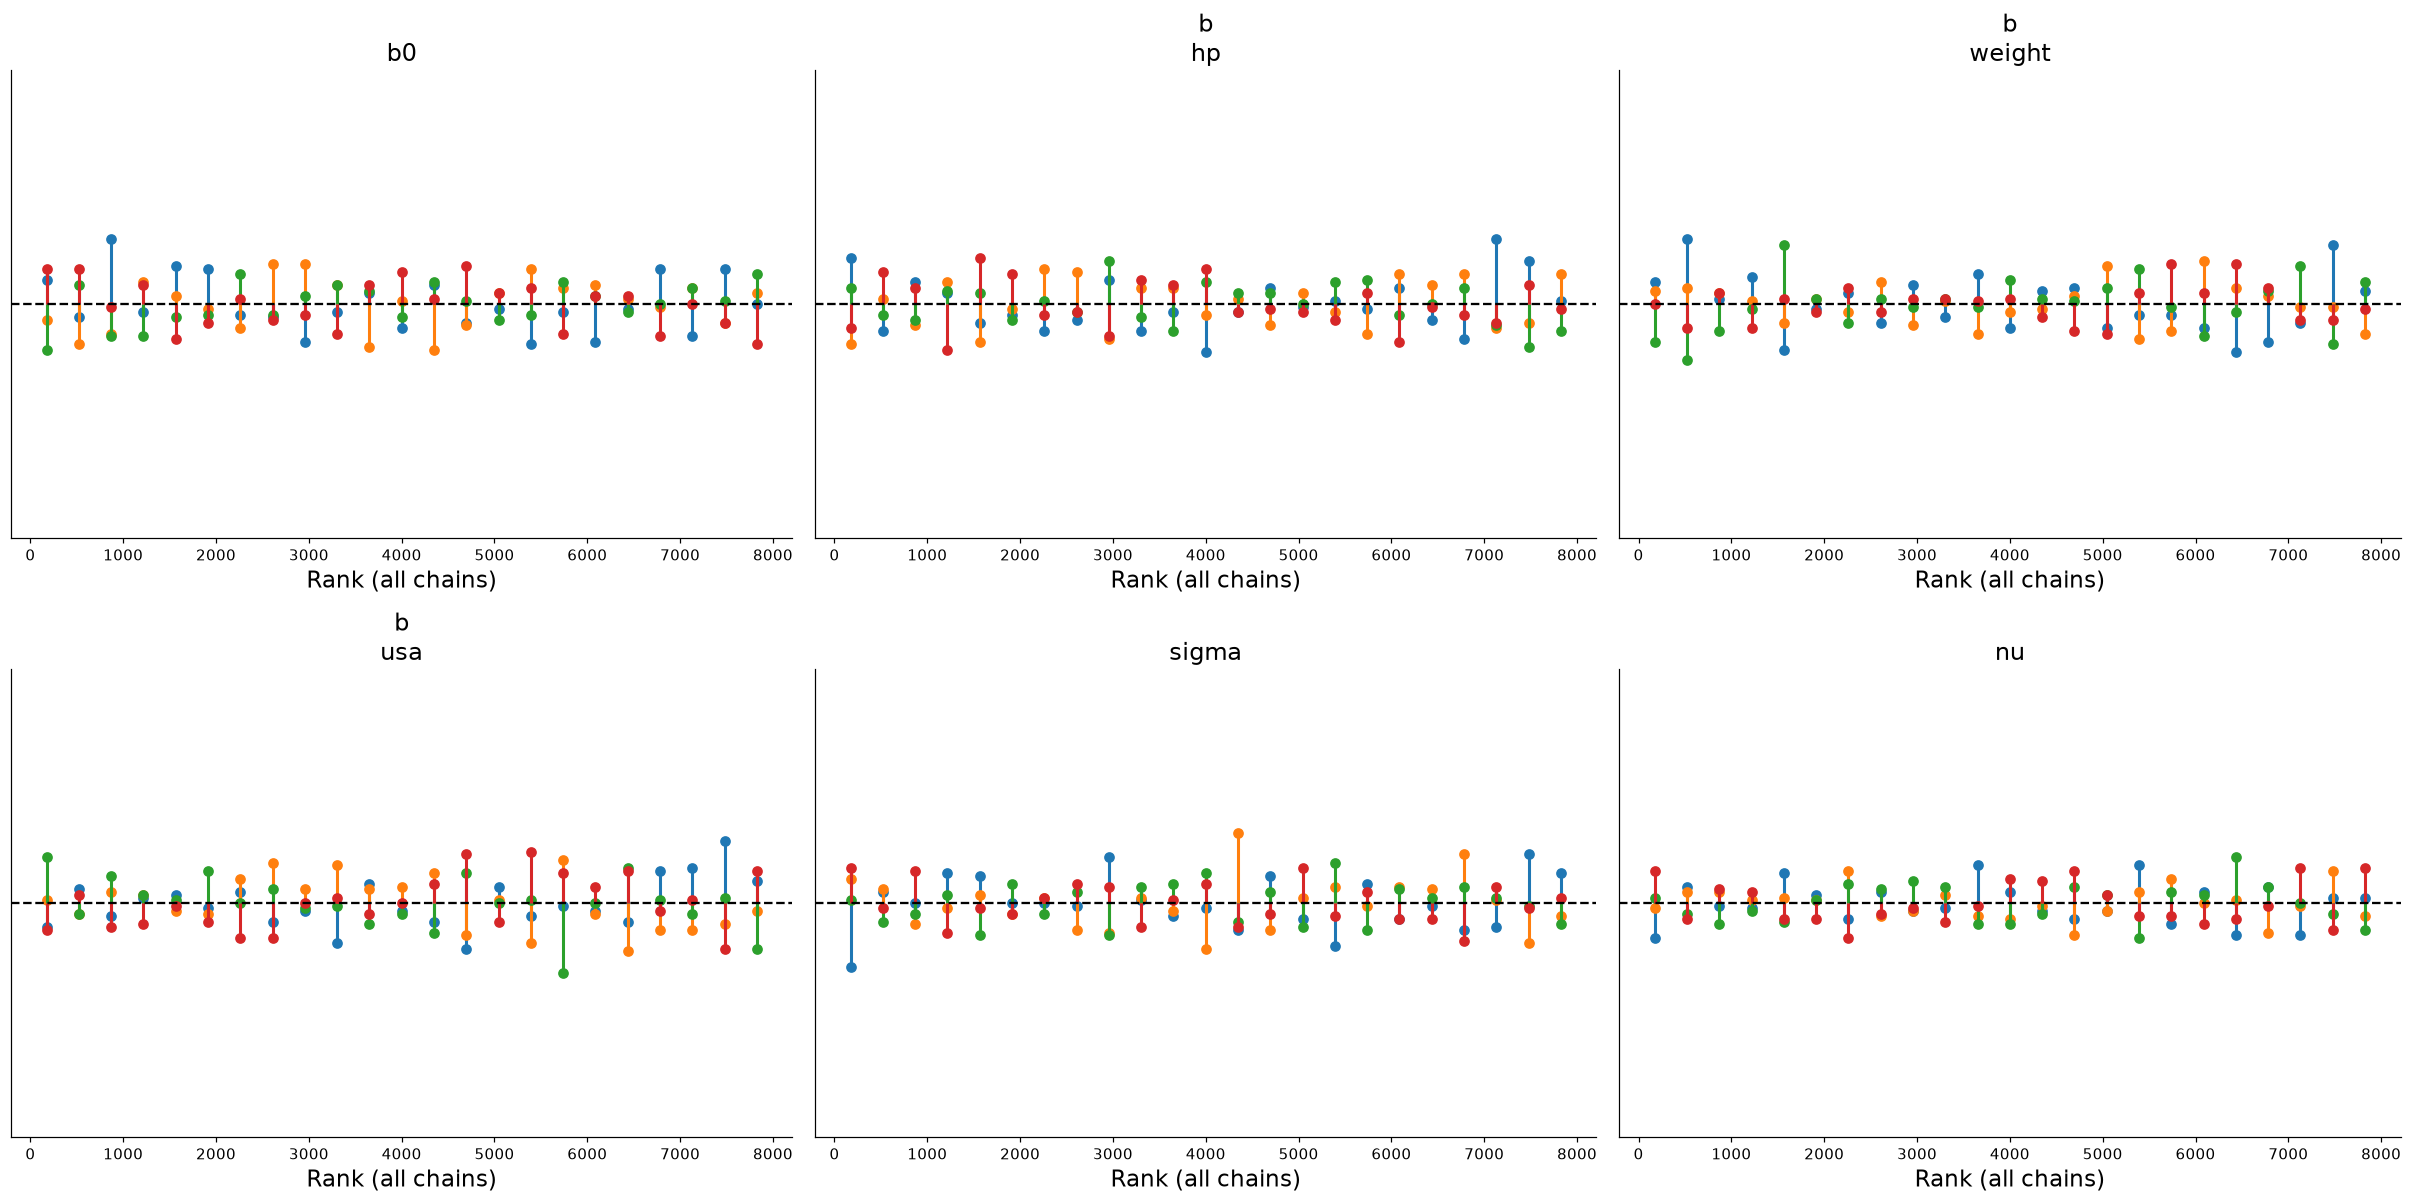

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_3_rank_M5.png


In [21]:
for name, idata in idatas.items():
    var_names = VARS + (["nu"] if name == "M5" else [])
    axes = az.plot_trace(idata, var_names=var_names, compact=True, figsize=(10, 2 * len(var_names)))
    fig = axes.ravel()[0].figure
    fig.tight_layout()  # ArviZ subplot titles otherwise touch the tick labels
    fig.suptitle(f"Hình 4.3 — Trace plot {name}", y=1.01)
    savefig(fig, f"fig_4_3_trace_{name}.png")

    axes = az.plot_rank(idata, var_names=var_names, kind="vlines")
    fig = np.ravel(axes)[0].figure
    fig.tight_layout()  # ArviZ subplot titles otherwise touch the tick labels
    fig.suptitle(f"Hình 4.3 — Rank plot {name}", y=1.01)
    savefig(fig, f"fig_4_3_rank_{name}.png")

## 4.4 Bảng tóm tắt hậu nghiệm (mean, sd, HDI 95%) và phân phối hậu nghiệm

In [22]:
rows = []
for name, idata in idatas.items():
    var_names = VARS + (["nu"] if name == "M5" else [])
    s = az.summary(idata, var_names=var_names, hdi_prob=.95)
    s.insert(0, "model", name)
    rows.append(s)
post = pd.concat(rows)
post.to_csv(TAB / "tab_4_4_posterior.csv")
print(post[["model", "mean", "sd", "hdi_2.5%", "hdi_97.5%", "ess_bulk", "r_hat"]].to_string())

          model   mean     sd  hdi_2.5%  hdi_97.5%  ess_bulk  r_hat
b0           M1  0.000  0.075    -0.151      0.144   11904.0    1.0
b[hp]        M1 -0.710  0.075    -0.859     -0.558   12101.0    1.0
sigma        M1  0.715  0.054     0.613      0.822   10830.0    1.0
b0           M2  0.210  0.104     0.009      0.411    6013.0    1.0
b[hp]        M2 -0.697  0.072    -0.835     -0.550    6669.0    1.0
b[usa]       M2 -0.406  0.143    -0.689     -0.129    6090.0    1.0
sigma        M2  0.688  0.053     0.588      0.792    7533.0    1.0
b0           M3  0.196  0.101     0.006      0.399    6385.0    1.0
b[hp]        M3 -0.859  0.107    -1.069     -0.651    5618.0    1.0
b[usa]       M3 -0.402  0.139    -0.686     -0.142    5988.0    1.0
b[hp_usa]    M3  0.294  0.144     0.026      0.590    5708.0    1.0
sigma        M3  0.675  0.052     0.580      0.781    6202.0    1.0
b0           M4  0.085  0.071    -0.063      0.215    5325.0    1.0
b[hp]        M4 -0.146  0.073    -0.289     -0.0

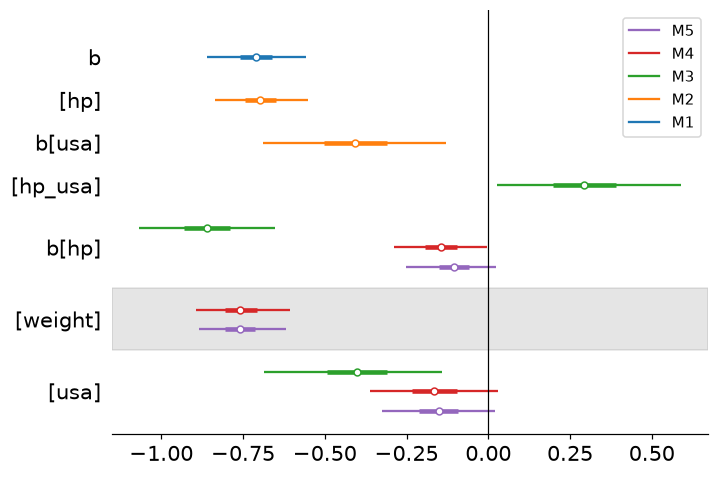

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_4_forest.png


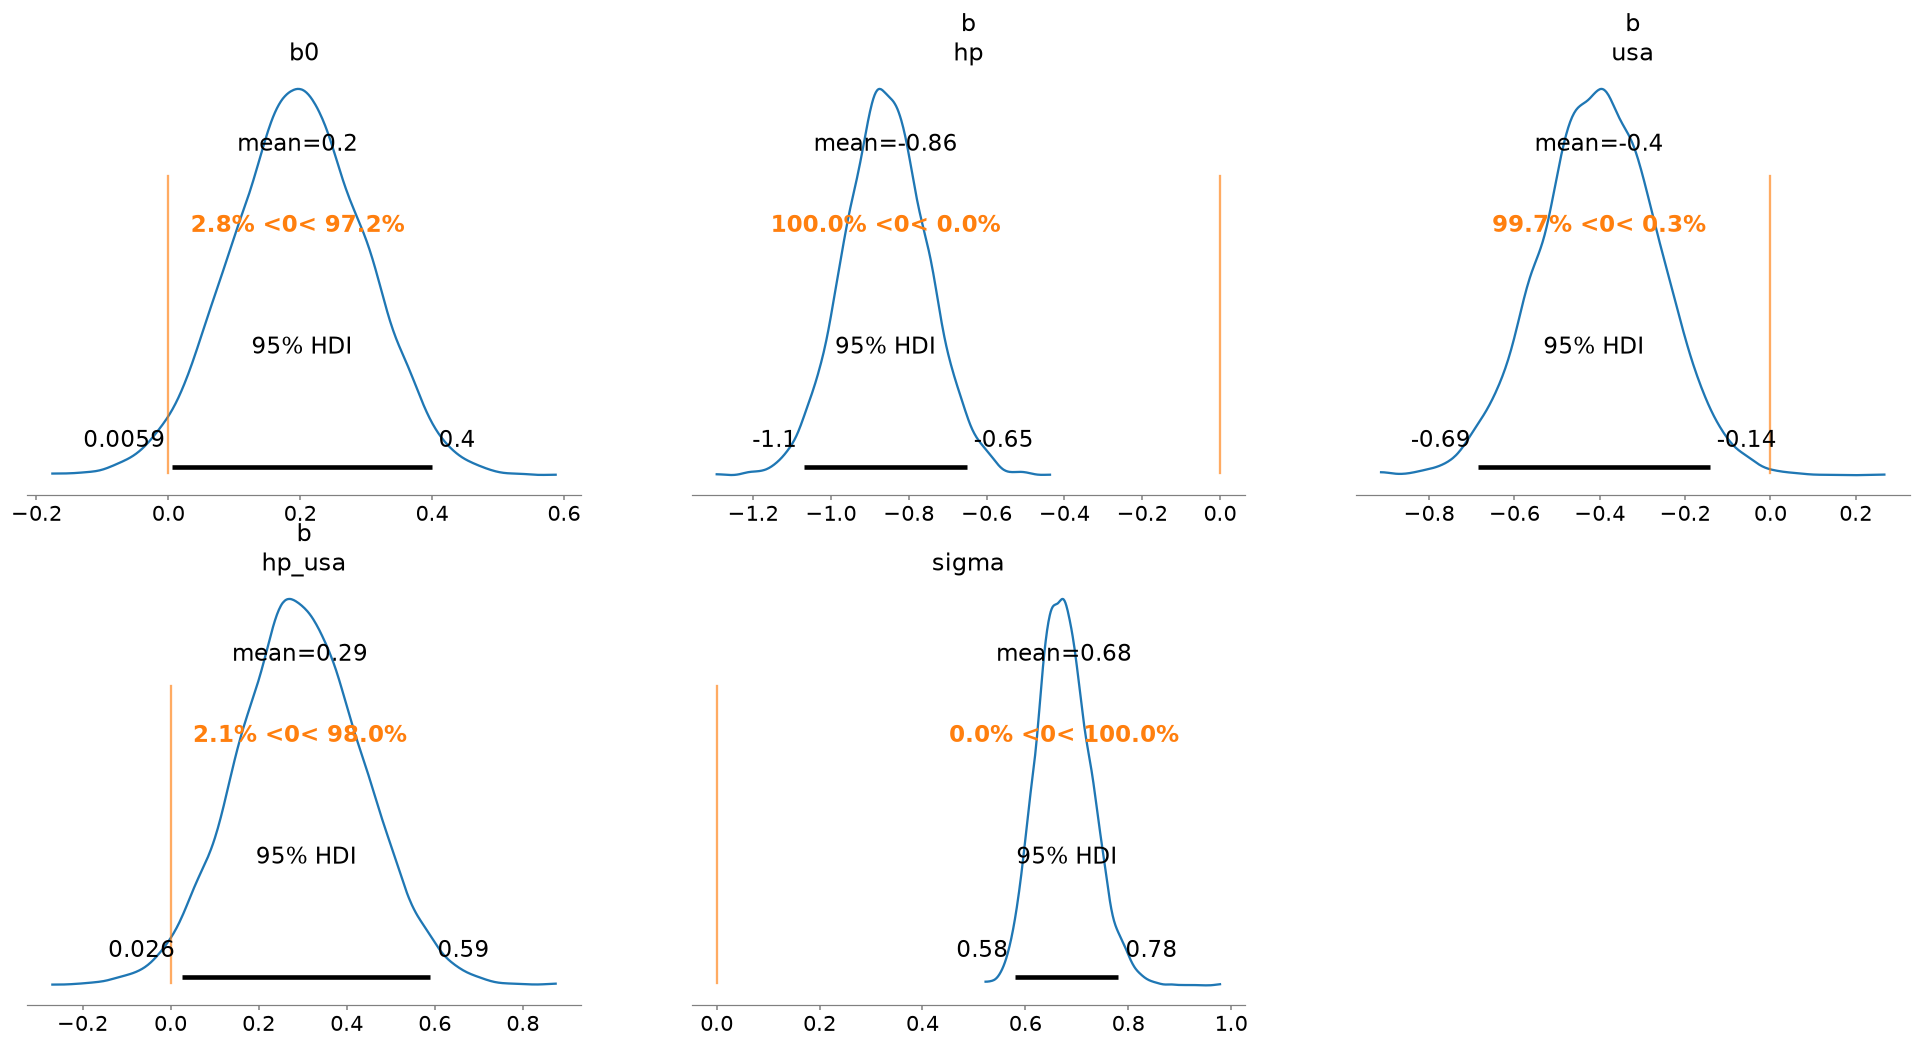

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_4_posterior_M3.png


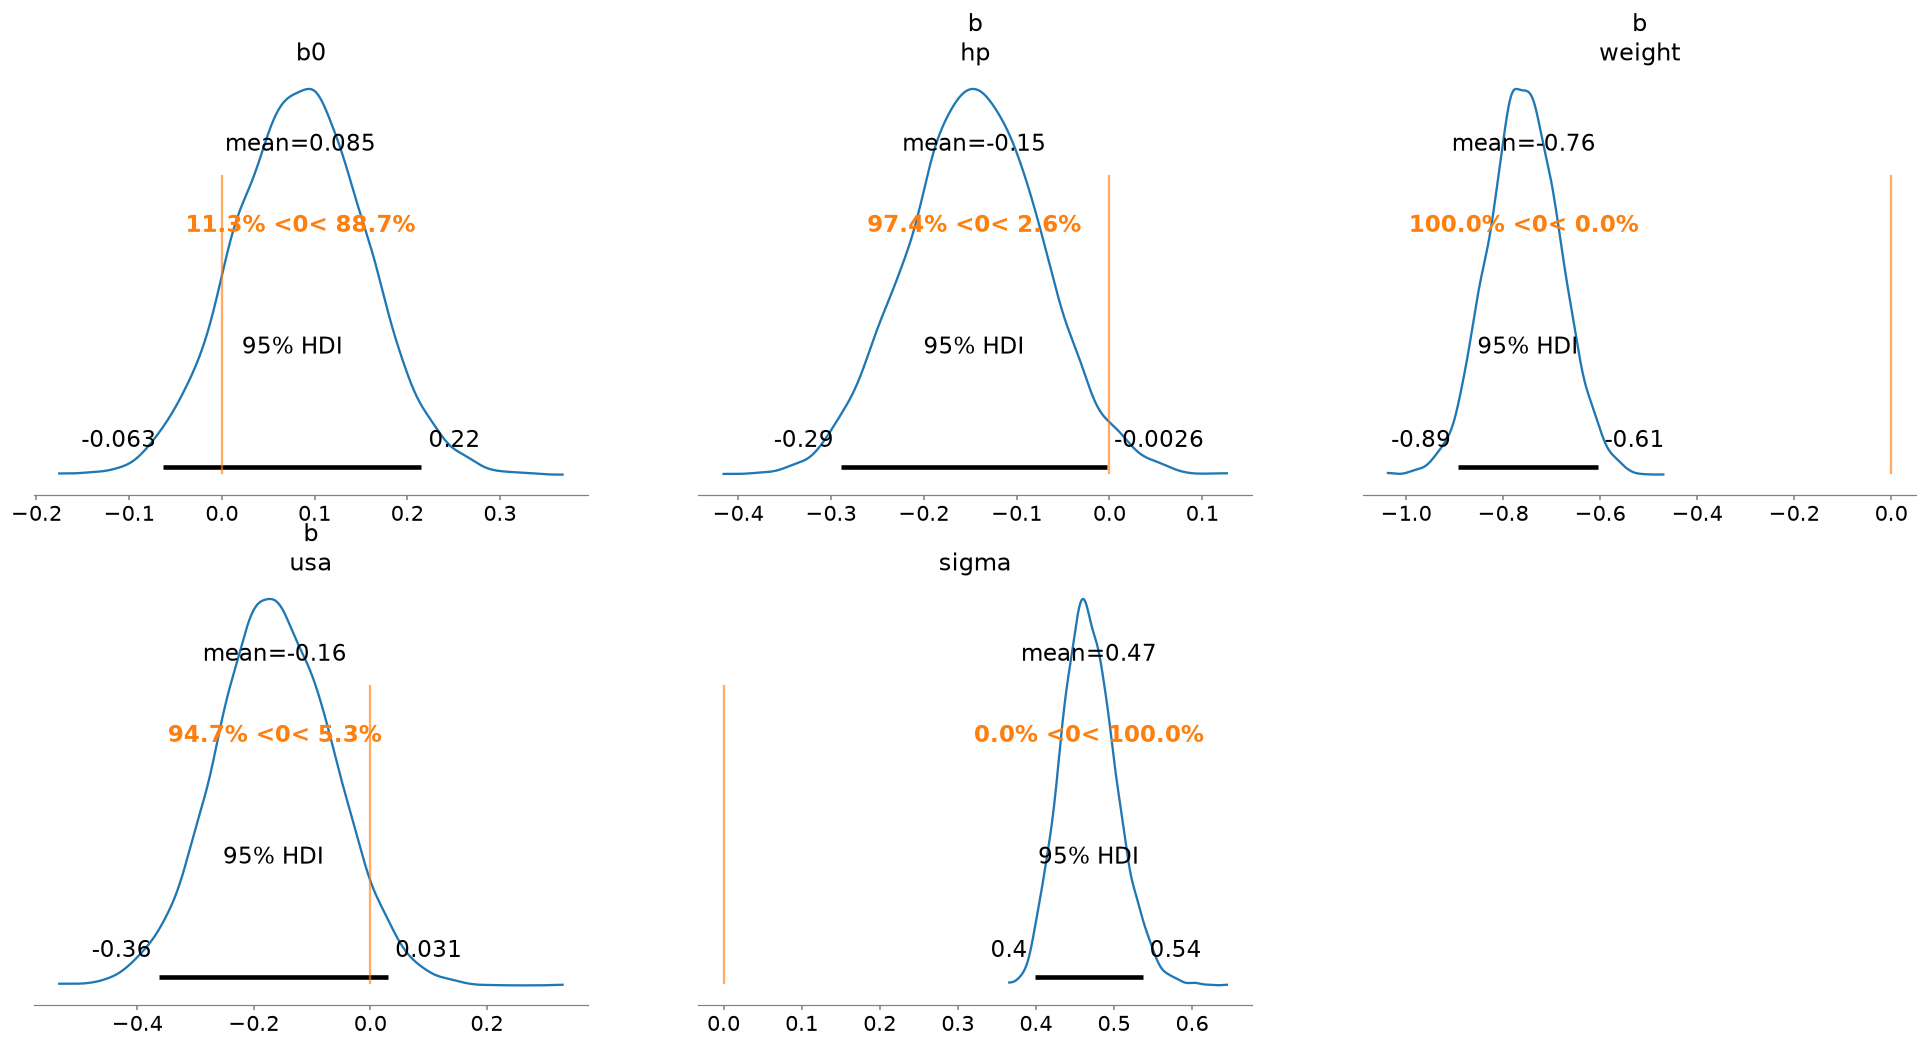

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_4_posterior_M4.png


In [23]:
fig, ax = plt.subplots(figsize=(7, 5))
az.plot_forest(list(idatas.values()), model_names=list(idatas), var_names=["b"],
               combined=True, hdi_prob=.95, ax=ax)
ax.axvline(0, c="k", lw=.8)
ax.set_title("Hình 4.4a — Hệ số hậu nghiệm M1–M5 (thang chuẩn hoá, HDI 95%)")
savefig(fig, "fig_4_4_forest.png")

for name in ["M3", m5_base]:
    axes = az.plot_posterior(idatas[name], var_names=VARS, hdi_prob=.95, ref_val=0)
    fig = np.ravel(axes)[0].figure
    fig.suptitle(f"Hình 4.4 — Phân phối hậu nghiệm {name}", y=1.02)
    savefig(fig, f"fig_4_4_posterior_{name}.png")

## 4.2 (minh hoạ) Random-walk Metropolis–Hastings cho M1, viết tay
Same priors as M1: b0, b1 ~ N(0, 2.5²), sigma ~ Half-Normal(1); sampled on (b0, b1, log sigma).

MH acceptance rates: [0.428 0.42  0.408 0.424]
             mean     sd  hdi_2.5%  hdi_97.5%  ess_bulk  r_hat
MH   b0     0.000  0.073    -0.146      0.135    1672.0    1.0
     b_hp  -0.708  0.074    -0.858     -0.567    1720.0    1.0
     sigma  0.714  0.052     0.621      0.824    1686.0    1.0
NUTS b0     0.000  0.075    -0.151      0.144   11904.0    1.0
     b_hp  -0.710  0.075    -0.859     -0.558   12101.0    1.0
     sigma  0.715  0.054     0.613      0.822   10830.0    1.0


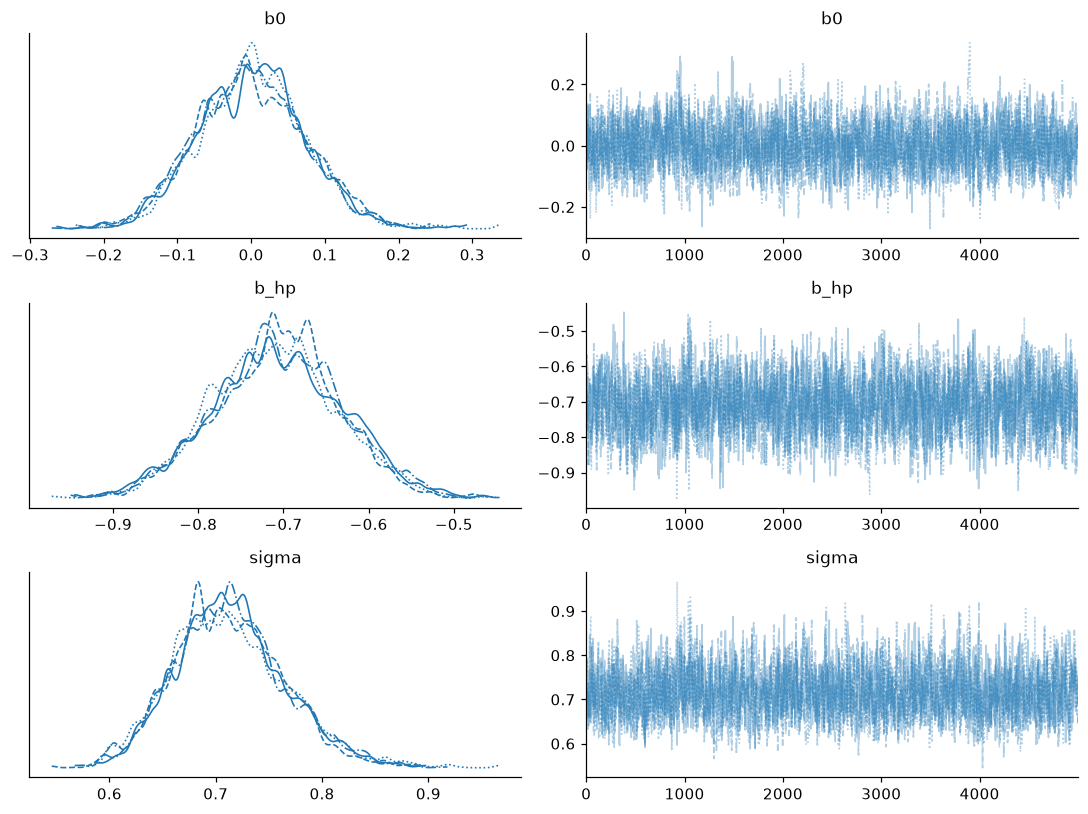

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_2_mh_trace.png


In [24]:
from scipy import stats

x = sc.hp(d["hp"])
y = sc.y(d["city"])


def log_post(theta):
    b0, b1, log_s = theta
    s = np.exp(log_s)
    return (stats.norm.logpdf(y, b0 + b1 * x, s).sum()
            + stats.norm.logpdf([b0, b1], 0, 2.5).sum()
            + stats.halfnorm.logpdf(s, scale=1) + log_s)  # + log|Jacobian| of sigma = exp(log_s)


def metropolis(n_iter, step, rng, start):
    chain = np.empty((n_iter, 3))
    cur, cur_lp, acc = np.array(start, float), log_post(start), 0
    for i in range(n_iter):
        prop = cur + step * rng.standard_normal(3)
        prop_lp = log_post(prop)
        if np.log(rng.uniform()) < prop_lp - cur_lp:
            cur, cur_lp, acc = prop, prop_lp, acc + 1
        chain[i] = cur
    return chain, acc / n_iter


rng = np.random.default_rng(SEED)
step = np.array([0.08, 0.08, 0.08])
chains, rates = [], []
for c in range(4):
    start = rng.normal(0, 1, 3)
    ch, rate = metropolis(6000, step, rng, start)
    chains.append(ch[1000:])  # 1000 burn-in
    rates.append(rate)
chains = np.stack(chains)
mh = az.from_dict(posterior={"b0": chains[..., 0], "b_hp": chains[..., 1],
                             "sigma": np.exp(chains[..., 2])})
mh_sum = az.summary(mh, hdi_prob=.95)
nuts_sum = az.summary(idatas["M1"], var_names=VARS, hdi_prob=.95)
nuts_sum.index = ["b0", "b_hp", "sigma"]
mh_cmp = pd.concat({"MH": mh_sum, "NUTS": nuts_sum})[["mean", "sd", "hdi_2.5%", "hdi_97.5%", "ess_bulk", "r_hat"]]
mh_cmp.to_csv(TAB / "tab_4_2_mh_vs_nuts.csv")
print("MH acceptance rates:", np.round(rates, 3))
print(mh_cmp.to_string())

axes = az.plot_trace(mh, compact=True, figsize=(10, 7.5))
fig = axes.ravel()[0].figure
fig.tight_layout()  # ArviZ subplot titles otherwise touch the tick labels
fig.suptitle("Hình 4.2 — Trace plot Metropolis–Hastings tự cài (M1)", y=1.01)
savefig(fig, "fig_4_2_mh_trace.png")

save_results(diagnostics=diag.to_dict("records"), mh_acceptance=[float(r) for r in rates],
             loo_rank_m1_m4=loo_rank["elpd_loo"].round(2).to_dict())

# 04_conjugate — Hậu nghiệm dạng đóng cho M1 (Normal–Inverse-Gamma), đối chiếu MCMC (mục 4.1)
Owner: Nguyễn Thục Anh. Runs after 03_sampling (needs `idata_M1.nc`).

Prior: beta | sigma² ~ N(m0, sigma² V0), sigma² ~ IG(a0, b0). Posterior:

V_n = (V0⁻¹ + XᵀX)⁻¹,  m_n = V_n (V0⁻¹ m0 + Xᵀy),
a_n = a0 + n/2,  b_n = b0 + ½ (yᵀy + m0ᵀV0⁻¹m0 − m_nᵀV_n⁻¹m_n)

Marginally beta | y ~ multivariate t_{2a_n}(m_n, (b_n/a_n) V_n) and sigma² | y ~ IG(a_n, b_n).

In [25]:
from common import *  # noqa: F401,F403
import pymc as pm
from scipy import stats

d = load_clean()
sc = Scaler(d)
X = np.column_stack([np.ones(len(d)), sc.hp(d["hp"])])
y = sc.y(d["city"])
n, p = X.shape

m0, V0 = np.zeros(p), np.eye(p) * 2.5**2
a0, b0 = 2.0, 1.0  # E[sigma²] = 1 on the standardised scale

V0_inv = np.linalg.inv(V0)
Vn = np.linalg.inv(V0_inv + X.T @ X)
mn = Vn @ (V0_inv @ m0 + X.T @ y)
an = a0 + n / 2
bn = b0 + 0.5 * (y @ y + m0 @ V0_inv @ m0 - mn @ np.linalg.inv(Vn) @ mn)

beta_scale = np.sqrt(np.diag(bn / an * Vn))
df = 2 * an
closed = pd.DataFrame({
    "mean": mn, "sd": beta_scale * np.sqrt(df / (df - 2)),
    "ci_2.5%": mn + stats.t.ppf(.025, df) * beta_scale,
    "ci_97.5%": mn + stats.t.ppf(.975, df) * beta_scale,
}, index=["b0", "b_hp"])
sig2 = stats.invgamma(an, scale=bn)
print(f"a_n = {an:.1f}, b_n = {bn:.3f}, E[sigma | y] ≈ {np.sqrt(sig2.mean()):.3f}")
print(closed.round(4))

a_n = 48.5, b_n = 23.764, E[sigma | y] ≈ 0.707
        mean      sd  ci_2.5%  ci_97.5%
b0    0.0000  0.0733  -0.1439    0.1439
b_hp -0.7101  0.0737  -0.8548   -0.5654


Check: the same NIG prior written in PyMC and sampled with NUTS must reproduce the
closed form; a mismatch would mean a coding error.

In [26]:
with pm.Model():
    sigma2 = pm.InverseGamma("sigma2", a0, b0)
    beta = pm.MvNormal("beta", m0, cov=sigma2 * V0)
    pm.Normal("y", X @ beta, pm.math.sqrt(sigma2), observed=y)
    nig_idata = pm.sample(**{**SAMPLE_KW, "idata_kwargs": {}})

nig_post = nig_idata.posterior["beta"].values.reshape(-1, p)
mcmc_nig = pd.DataFrame({"mean": nig_post.mean(0), "sd": nig_post.std(0),
                         "ci_2.5%": np.quantile(nig_post, .025, 0),
                         "ci_97.5%": np.quantile(nig_post, .975, 0)}, index=["b0", "b_hp"])

m1 = load_idata("M1").posterior
m1_post = np.column_stack([m1["b0"].values.ravel(), m1["b"].sel(term="hp").values.ravel()])
mcmc_m1 = pd.DataFrame({"mean": m1_post.mean(0), "sd": m1_post.std(0),
                        "ci_2.5%": np.quantile(m1_post, .025, 0),
                        "ci_97.5%": np.quantile(m1_post, .975, 0)}, index=["b0", "b_hp"])

cmp = pd.concat({"closed form (NIG)": closed, "NUTS, NIG prior": mcmc_nig,
                 "NUTS, M1 weak prior": mcmc_m1})
cmp.to_csv(TAB / "tab_4_1_conjugate_vs_mcmc.csv")
print(cmp.round(4).to_string())

max_diff = float(np.abs(closed["mean"] - mcmc_nig["mean"]).max())
assert max_diff < 0.01, f"closed form and MCMC disagree by {max_diff:.4f}"

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [sigma2, beta]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 21 seconds.


                            mean      sd  ci_2.5%  ci_97.5%
closed form (NIG)   b0    0.0000  0.0733  -0.1439    0.1439
                    b_hp -0.7101  0.0737  -0.8548   -0.5654
NUTS, NIG prior     b0   -0.0000  0.0730  -0.1411    0.1433
                    b_hp -0.7099  0.0742  -0.8571   -0.5644
NUTS, M1 weak prior b0    0.0001  0.0754  -0.1490    0.1475
                    b_hp -0.7103  0.0754  -0.8617   -0.5602


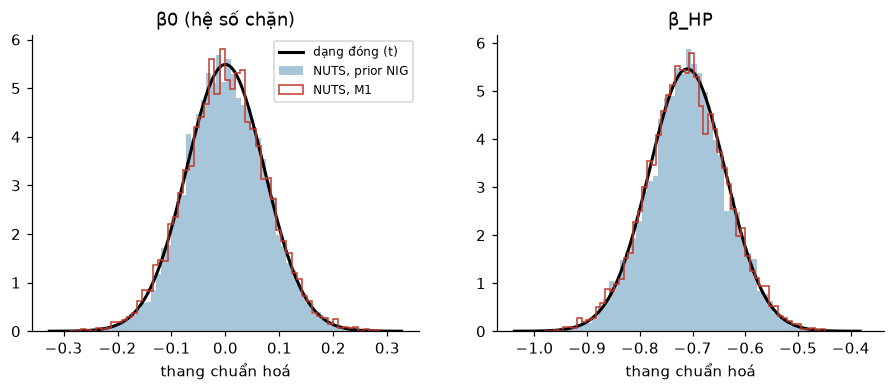

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_4_1_conjugate.png


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, (ax, label) in enumerate(zip(axes, ["β0 (hệ số chặn)", "β_HP"])):
    grid = np.linspace(mn[j] - 4.5 * beta_scale[j], mn[j] + 4.5 * beta_scale[j], 300)
    ax.plot(grid, stats.t.pdf(grid, df, mn[j], beta_scale[j]), c="k", lw=2, label="dạng đóng (t)")
    ax.hist(nig_post[:, j], bins=60, density=True, alpha=.4, color="#2471a3", label="NUTS, prior NIG")
    ax.hist(m1_post[:, j], bins=60, density=True, histtype="step", color="#c0392b", label="NUTS, M1")
    ax.set(title=label, xlabel="thang chuẩn hoá")
axes[0].legend(fontsize=8)
fig.suptitle("Hình 4.1 — Hậu nghiệm dạng đóng và MCMC cho M1")
savefig(fig, "fig_4_1_conjugate.png")

save_results(conjugate={"a_n": an, "b_n": float(bn), "m_n": mn.tolist(),
                        "max_abs_mean_diff_vs_nuts": max_diff})

# 05_evaluation — PPC, so sánh mô hình, trả lời Q1–Q4 (Chương 5)
Owner: Nguyễn Hồng Phúc. Runs after 03_sampling.

In [28]:
from common import *  # noqa: F401,F403
import arviz as az
from scipy import stats

d = load_clean()
sc = Scaler(d)
spec = model_spec()
idatas = {name: load_idata(name) for name in spec}


def draws(idata, terms):
    post = idata.posterior.stack(sample=("chain", "draw"))
    b = post["b"].sel(term=terms).values  # (terms, S)
    nu = post["nu"].values if "nu" in post else None
    return post["b0"].values, b, post["sigma"].values, nu


def predict_mpg(name, hp, weight, usa, kind="pred", seed=SEED):
    """Posterior draws (S, n) in MPG of exp(mu) ('mu') or a new observation ('pred').

    The response is log(City), so exp(mu) is the conditional *median* of City, not its mean;
    under the Student-t likelihood the mean of City does not even exist.
    """
    s = spec[name]
    b0, b, sigma, nu = draws(idatas[name], s["terms"])
    X = design(None, sc, s["terms"], hp=hp, weight=weight, usa=usa)
    mu = b0[:, None] + (X @ b).T
    if kind == "mu":
        return sc.to_mpg(mu)
    rng = np.random.default_rng(seed)
    eps = rng.standard_normal(mu.shape) if nu is None else rng.standard_t(nu[:, None], mu.shape)
    return sc.to_mpg(mu + sigma[:, None] * eps)


def hdi(x, prob=.95):
    return az.hdi(np.asarray(x), hdi_prob=prob)

## 5.1 Posterior predictive check (thang MPG)

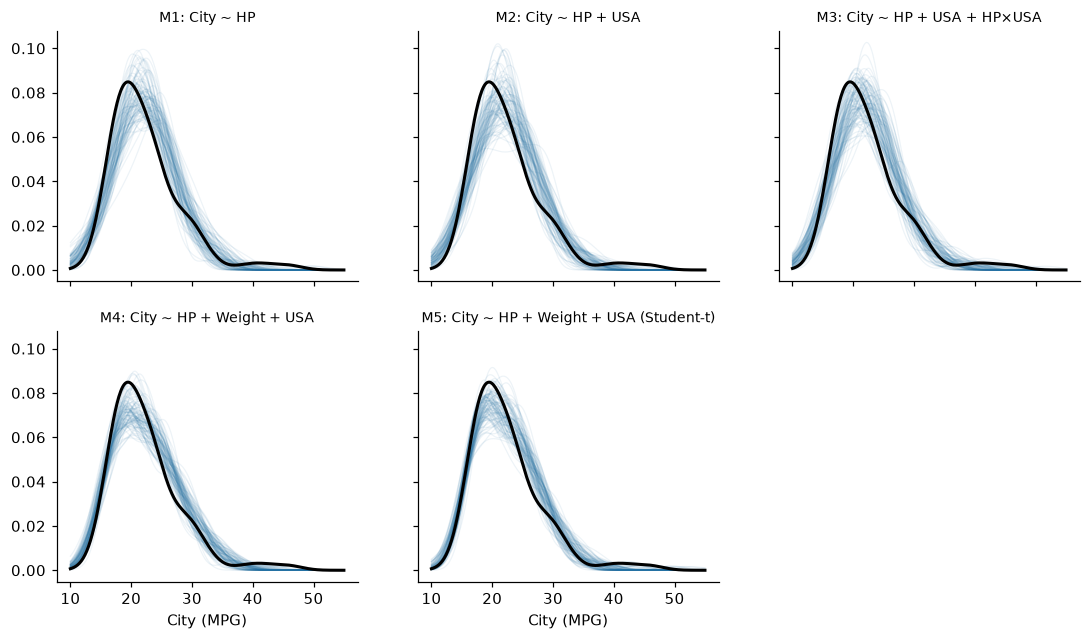

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_5_1_ppc.png


stat     max   mean    min     sd
model                            
M1     0.012  0.462  0.002  0.086
M2     0.013  0.463  0.002  0.086
M3     0.024  0.470  0.004  0.138
M4     0.006  0.464  0.021  0.094
M5     0.041  0.384  0.044  0.063


In [29]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
grid = np.linspace(10, 55, 300)
rng = np.random.default_rng(SEED)
for ax, name in zip(axes.ravel(), spec):
    rep = sc.to_mpg(idatas[name].posterior_predictive["y"].stack(s=("chain", "draw")).values.T)
    for i in rng.choice(len(rep), 100, replace=False):
        ax.plot(grid, stats.gaussian_kde(rep[i])(grid), c="#2471a3", alpha=.08, lw=.8)
    ax.plot(grid, stats.gaussian_kde(d["city"])(grid), c="k", lw=2)
    ax.set_title(f"{name}: {spec[name]['formula']}", fontsize=9)
axes.ravel()[-1].axis("off")
for ax in axes[-1]:
    ax.set_xlabel("City (MPG)")
fig.suptitle("Hình 5.1 — Posterior predictive check: dữ liệu thật (đen) và 100 bộ tái tạo (xanh)")
savefig(fig, "fig_5_1_ppc.png")

# Bayesian p-values for a few statistics (near 0 or 1 = the model misses that feature).
ppp_rows = []
for name in spec:
    rep = sc.to_mpg(idatas[name].posterior_predictive["y"].stack(s=("chain", "draw")).values.T)
    for stat, f in [("mean", np.mean), ("sd", np.std), ("max", np.max), ("min", np.min)]:
        ppp_rows.append({"model": name, "stat": stat, "observed": f(d["city"]),
                         "p_value": np.mean(f(rep, axis=1) >= f(d["city"]))})
ppp = pd.DataFrame(ppp_rows).pivot(index="model", columns="stat", values="p_value")
ppp.to_csv(TAB / "tab_5_1_ppc_pvalues.csv")
print(ppp.round(3))

## 5.2 So sánh mô hình: PSIS-LOO (ELPD) và WAIC

/Users/huybq/Documents/work stuff/special-topic/.venv/lib/python3.12/site-packages/arviz/stats/stats.py:1652: UserWarning: For one or more samples the posterior variance of the log predictive densities exceeds 0.4. This could be indication of WAIC starting to fail. 
See http://arxiv.org/abs/1507.04544 for details
  warnings.warn(
/Users/huybq/Documents/work stuff/special-topic/.venv/lib/python3.12/site-packages/arviz/stats/stats.py:1652: UserWarning: For one or more samples the posterior variance of the log predictive densities exceeds 0.4. This could be indication of WAIC starting to fail. 
See http://arxiv.org/abs/1507.04544 for details
  warnings.warn(
/Users/huybq/Documents/work stuff/special-topic/.venv/lib/python3.12/site-packages/arviz/stats/stats.py:1652: UserWarning: For one or more samples the posterior variance of the log predictive densities exceeds 0.4. This could be indication of WAIC starting to fail. 
See http://arxiv.org/abs/1507.04544 for details
  warnings.warn(
/Use

    rank  elpd_loo  p_loo  elpd_diff     se   dse  weight
M5     0    -59.78   6.37       0.00   9.89  0.00    0.97
M4     1    -64.24   6.65       4.45  10.71  2.60    0.00
M3     2    -98.17   5.98      38.39   8.23  8.35    0.00
M2     3    -99.34   5.07      39.56   8.76  8.24    0.03
M1     4   -102.43   4.10      42.65   8.94  7.83    0.00
    rank  elpd_waic  p_waic  elpd_diff     se   dse
M5     0     -59.72    6.31       0.00   9.86  0.00
M4     1     -64.15    6.56       4.43  10.67  2.59
M3     2     -98.10    5.91      38.39   8.22  8.34
M2     3     -99.29    5.02      39.58   8.74  8.24
M1     4    -102.41    4.08      42.69   8.93  7.82


    k_gt_0.7  k_gt_0.5     max_k
M1       0.0       0.0  0.472658
M2       0.0       0.0  0.447987
M3       0.0       0.0  0.476027
M4       0.0       1.0  0.543214
M5       0.0       0.0  0.457354


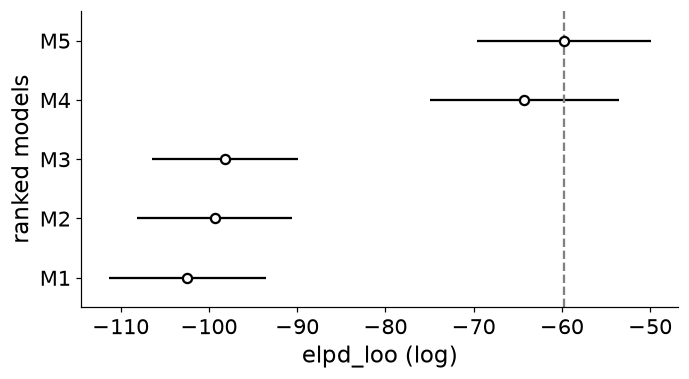

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_5_2_compare.png
Final model: M5 - rank 1 by PSIS-LOO; M4 is 4.45 ELPD behind (dse 2.60, 1.7 SE)


In [30]:
cmp_loo = az.compare(idatas, ic="loo")
cmp_waic = az.compare(idatas, ic="waic")
cmp_loo.to_csv(TAB / "tab_5_2_compare_loo.csv")
cmp_waic.to_csv(TAB / "tab_5_2_compare_waic.csv")
print(cmp_loo[["rank", "elpd_loo", "p_loo", "elpd_diff", "se", "dse", "weight"]].round(2))
print(cmp_waic[["rank", "elpd_waic", "p_waic", "elpd_diff", "se", "dse"]].round(2))

pareto = {}
for name, idata in idatas.items():
    k = az.loo(idata, pointwise=True).pareto_k.values
    pareto[name] = {"k_gt_0.7": int((k > .7).sum()), "k_gt_0.5": int((k > .5).sum()), "max_k": float(k.max())}
print(pd.DataFrame(pareto).T)

fig, ax = plt.subplots(figsize=(7, 3.5))
az.plot_compare(cmp_loo, ax=ax, insample_dev=False)
ax.set_title("Hình 5.2 — So sánh mô hình bằng PSIS-LOO")
savefig(fig, "fig_5_2_compare.png")

FINAL = cmp_loo.index[0]
# The top-ranked model is final; flag it when the runner-up is within 2 dSE.
runner_up = cmp_loo.index[1]
gap, dse = cmp_loo.loc[runner_up, "elpd_diff"], cmp_loo.loc[runner_up, "dse"]
note = f"rank 1 by PSIS-LOO; {runner_up} is {gap:.2f} ELPD behind (dse {dse:.2f}, {gap / dse:.1f} SE)"
print("Final model:", FINAL, "-", note)

## 5.3 Q1 — Quan hệ giữa các biến: diễn giải β_HP
On the log scale, +10 hp multiplies City by exp(10 · β_HP · sd_logy / sd_hp).

In [31]:
def pct_per_10hp(name):
    b_hp = idatas[name].posterior["b"].sel(term="hp").values.ravel()
    return 100 * (np.exp(10 * b_hp * sc.y_sd / sc.hp_sd) - 1)


q1 = {}
for name in ["M1", FINAL]:
    pct = pct_per_10hp(name)
    lo, hi = hdi(pct)
    q1[name] = {"pct_per_10hp_mean": pct.mean(), "hdi_low": lo, "hdi_high": hi,
                "p_negative": float(np.mean(pct < 0))}
    print(f"{name}: +10 hp -> City {pct.mean():+.2f}% (HDI 95% {lo:+.2f}%, {hi:+.2f}%)")

# Absolute effect for a median car (140 -> 150 hp), from M1 (HP only).
mu140, mu150 = (predict_mpg("M1", hp, None, 0, kind="mu")[:, 0] for hp in (140, 150))
diff = mu150 - mu140
q1["M1_mpg_140_to_150"] = {"mean": diff.mean(), "hdi": hdi(diff).tolist()}
print(f"M1: 140 -> 150 hp changes City by {diff.mean():+.2f} MPG (HDI {hdi(diff).round(2)})")

if "weight" in spec[FINAL]["terms"]:
    b_w = idatas[FINAL].posterior["b"].sel(term="weight").values.ravel()
    pct_100kg = 100 * (np.exp(100 * b_w * sc.y_sd / sc.w_sd) - 1)
    q1["weight_pct_per_100kg"] = {"mean": pct_100kg.mean(), "hdi": hdi(pct_100kg).tolist()}
    print(f"{FINAL}: +100 kg -> City {pct_100kg.mean():+.2f}% (HDI {hdi(pct_100kg).round(2)})")

M1: +10 hp -> City -2.99% (HDI 95% -3.61%, -2.36%)
M5: +10 hp -> City -0.45% (HDI 95% -1.07%, +0.10%)
M1: 140 -> 150 hp changes City by -0.66 MPG (HDI [-0.8  -0.52])
M5: +100 kg -> City -6.15% (HDI [-7.14 -5.05])


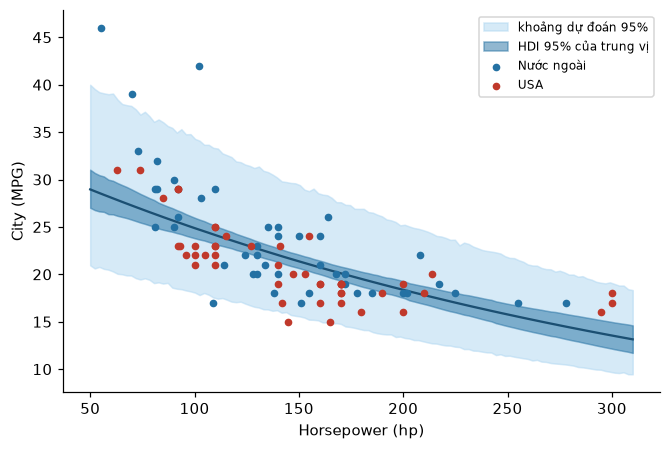

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_5_3_q1_m1_fit.png


In [32]:
fig, ax = plt.subplots(figsize=(7, 4.5))
hp_grid = np.linspace(50, 310, 120)
mu = predict_mpg("M1", hp_grid, None, 0, kind="mu")
pred = predict_mpg("M1", hp_grid, None, 0, kind="pred")
ax.fill_between(hp_grid, *np.quantile(pred, [.025, .975], axis=0), color="#aed6f1", alpha=.5,
                label="khoảng dự đoán 95%")
band = np.array([hdi(mu[:, i]) for i in range(len(hp_grid))])
ax.fill_between(hp_grid, band[:, 0], band[:, 1], color="#2471a3", alpha=.5, label="HDI 95% của trung vị")
ax.plot(hp_grid, np.median(mu, 0), c="#1b4f72")
for o, sub in d.groupby("origin"):
    ax.scatter(sub["hp"], sub["city"], s=16, c=COLOR[o], label=o, zorder=3)
ax.set(xlabel="Horsepower (hp)", ylabel="City (MPG)", title="Hình 5.3 — M1: City theo HP")
ax.legend(fontsize=8)
savefig(fig, "fig_5_3_q1_m1_fit.png")

## 5.4 Q2 — Xe Mỹ và xe nước ngoài

In [33]:
q2 = {}
for name in ["M2", "M3", FINAL]:
    post = idatas[name].posterior["b"]
    b_usa = post.sel(term="usa").values.ravel()
    entry = {"b_usa_mean": b_usa.mean(), "b_usa_hdi": hdi(b_usa).tolist(),
             "p_b_usa_gt_0": float(np.mean(b_usa > 0)),
             "pct_effect_usa": 100 * (np.exp(b_usa.mean() * sc.y_sd) - 1)}
    if "hp_usa" in spec[name]["terms"]:
        b_int = post.sel(term="hp_usa").values.ravel()
        entry.update(b_hp_usa_mean=b_int.mean(), b_hp_usa_hdi=hdi(b_int).tolist(),
                     p_b_hp_usa_gt_0=float(np.mean(b_int > 0)))
    q2[name] = entry
    print(name, {k: np.round(v, 3) for k, v in entry.items()})

M2 {'b_usa_mean': np.float64(-0.406), 'b_usa_hdi': array([-0.689, -0.129]), 'p_b_usa_gt_0': np.float64(0.002), 'pct_effect_usa': np.float64(-8.693)}
M3 {'b_usa_mean': np.float64(-0.402), 'b_usa_hdi': array([-0.686, -0.142]), 'p_b_usa_gt_0': np.float64(0.003), 'pct_effect_usa': np.float64(-8.6), 'b_hp_usa_mean': np.float64(0.294), 'b_hp_usa_hdi': array([0.026, 0.59 ]), 'p_b_hp_usa_gt_0': np.float64(0.98)}
M5 {'b_usa_mean': np.float64(-0.152), 'b_usa_hdi': array([-0.325,  0.021]), 'p_b_usa_gt_0': np.float64(0.043), 'pct_effect_usa': np.float64(-3.346)}


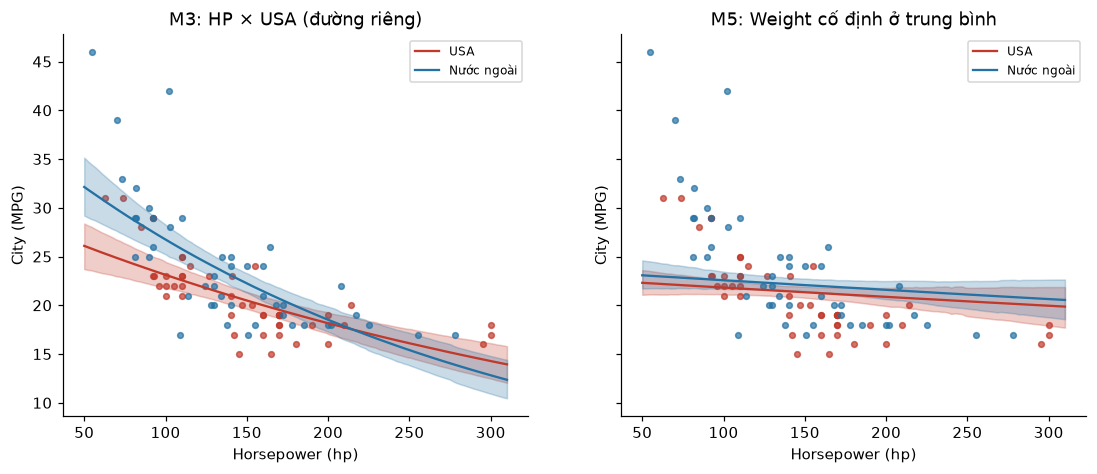

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_5_4_q2_usa.png


In [34]:
panels = [("M3", None, "M3: HP × USA (đường riêng)")]
if "weight" in spec[FINAL]["terms"]:
    panels.append((FINAL, d["weight"].mean(), f"{FINAL}: Weight cố định ở trung bình"))
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4.5), sharey=True, squeeze=False)
for ax, (name, w, title) in zip(axes[0], panels):
    for usa, o in [(1, "USA"), (0, "Nước ngoài")]:
        mu = predict_mpg(name, hp_grid, w, usa, kind="mu")
        band = np.array([hdi(mu[:, i]) for i in range(len(hp_grid))])
        ax.fill_between(hp_grid, band[:, 0], band[:, 1], color=COLOR[o], alpha=.25)
        ax.plot(hp_grid, np.median(mu, 0), c=COLOR[o], label=o)
        sub = d[d["usa"] == usa]
        ax.scatter(sub["hp"], sub["city"], s=14, c=COLOR[o], alpha=.7)
    ax.set(xlabel="Horsepower (hp)", ylabel="City (MPG)", title=title)
    ax.legend(fontsize=8)
fig.suptitle("Hình 5.4 — Đường hồi quy và HDI 95% cho xe Mỹ và xe nước ngoài")
savefig(fig, "fig_5_4_q2_usa.png")

## 5.5 Q3 — Ngoại lai: phần dư chuẩn hoá, Pareto-k, Normal vs Student-t

In [35]:
normal_name = spec["M5"]["base"]  # the Normal model M5 robustifies
post = idatas[normal_name].posterior
mu_mean = post["mu"].mean(("chain", "draw")).values
resid_std = (sc.y(d["city"]) - mu_mean) / post["sigma"].mean().item()
k_vals = az.loo(idatas[normal_name], pointwise=True).pareto_k.values
k_vals_m5 = az.loo(idatas["M5"], pointwise=True).pareto_k.values
fitted_mpg = sc.to_mpg(mu_mean)

out = d[["name", "type", "origin", "hp", "weight", "engine_size", "city", "price_max"]].copy()
out["type"] = out["type"].map(TYPE_LABEL)
out["fitted_mpg"] = fitted_mpg.round(1)
out["std_resid"] = resid_std.round(2)
out[f"pareto_k_{normal_name}"] = k_vals.round(2)
out["pareto_k_M5"] = k_vals_m5.round(2)
CANDIDATES = ["Geo Metro", "Honda Civic", "Suzuki Swift", "Mazda RX-7", "Mercedes-Benz 300E"]
flag = (np.abs(resid_std) > 2) | (k_vals > .5) | out["name"].isin(CANDIDATES) | (out["type"] == "Van")
outliers = out[flag].sort_values("std_resid")
outliers.to_csv(TAB / "tab_5_5_outliers.csv", index=False)
print(outliers.to_string(index=False))

                 name    type     origin  hp  weight  engine_size  city  price_max  fitted_mpg  std_resid  pareto_k_M4  pareto_k_M5
   Volkswagen Corrado  Sporty Nước ngoài 178    1275          2.8    18       23.7        23.4      -2.52         0.19         0.09
           Mazda RX-7  Sporty Nước ngoài 255    1313          1.3    17       32.5        21.8      -2.37         0.29         0.25
        Ford Aerostar     Van        USA 145    1694          3.0    15       25.3        17.7      -1.57         0.10        -0.05
      Chevrolet Astro     Van        USA 165    1826          4.3    15       18.6        16.1      -0.65         0.21         0.02
        Dodge Caravan     Van        USA 142    1681          3.0    17       24.4        17.9      -0.47         0.17         0.02
   Volkswagen Eurovan     Van Nước ngoài 109    1796          2.5    17       22.7        17.6      -0.32         0.21         0.07
            Mazda MPV     Van Nước ngoài 155    1694          3.0    18     

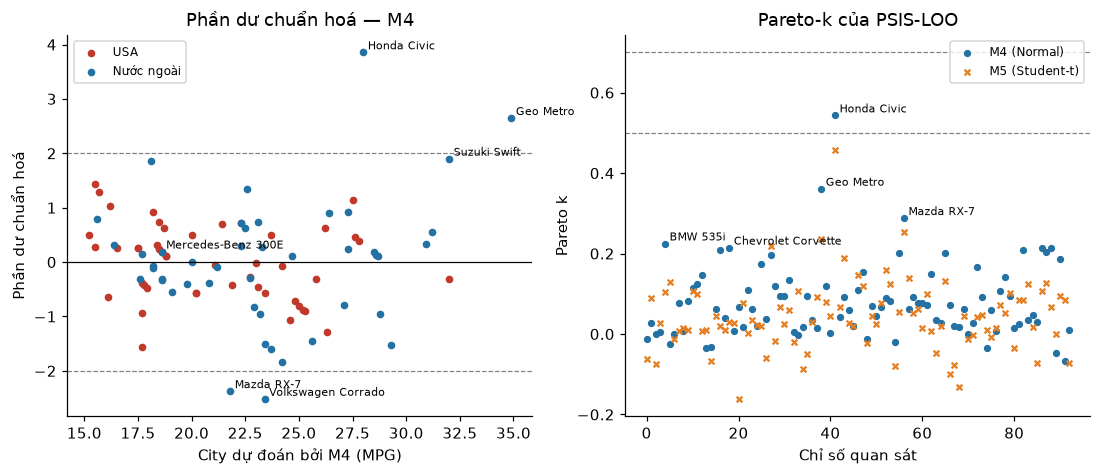

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_5_5_q3_outliers.png


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for o in COLOR:
    m = out["origin"] == o
    ax.scatter(out.loc[m, "fitted_mpg"], resid_std[m], s=16, c=COLOR[o], label=o)
ax.axhline(0, c="k", lw=.8)
for yv in (-2, 2):
    ax.axhline(yv, c="grey", ls="--", lw=.8)
for i in np.where((np.abs(resid_std) > 2) | out["name"].isin(CANDIDATES))[0]:
    ax.annotate(out["name"].iat[i], (out["fitted_mpg"].iat[i], resid_std[i]), fontsize=7,
                xytext=(3, 2), textcoords="offset points")
ax.set(xlabel=f"City dự đoán bởi {normal_name} (MPG)", ylabel="Phần dư chuẩn hoá",
       title=f"Phần dư chuẩn hoá — {normal_name}")
ax.legend(fontsize=8)
ax = axes[1]
ax.scatter(np.arange(len(d)), k_vals, s=14, c="#2471a3", label=f"{normal_name} (Normal)")
ax.scatter(np.arange(len(d)), k_vals_m5, s=14, c="#e67e22", marker="x", label="M5 (Student-t)")
for yv in (.5, .7):
    ax.axhline(yv, c="grey", ls="--", lw=.8)
for i in np.argsort(k_vals)[-5:]:
    ax.annotate(out["name"].iat[i], (i, k_vals[i]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set(xlabel="Chỉ số quan sát", ylabel="Pareto k", title="Pareto-k của PSIS-LOO")
ax.legend(fontsize=8)
fig.suptitle("Hình 5.5 — Các điểm ngoại lai")
savefig(fig, "fig_5_5_q3_outliers.png")

In [37]:
coef_shift = pd.concat({
    normal_name: az.summary(idatas[normal_name], var_names=["b0", "b", "sigma"], hdi_prob=.95),
    "M5": az.summary(idatas["M5"], var_names=["b0", "b", "sigma", "nu"], hdi_prob=.95),
})[["mean", "sd", "hdi_2.5%", "hdi_97.5%"]]
coef_shift.to_csv(TAB / "tab_5_5_normal_vs_student.csv")
print(coef_shift.round(3).to_string())

               mean     sd  hdi_2.5%  hdi_97.5%
M4 b0         0.085  0.071    -0.063      0.215
   b[hp]     -0.146  0.073    -0.289     -0.003
   b[weight] -0.757  0.074    -0.893     -0.605
   b[usa]    -0.164  0.101    -0.363      0.031
   sigma      0.468  0.036     0.398      0.537
M5 b0         0.072  0.066    -0.057      0.200
   b[hp]     -0.105  0.070    -0.251      0.022
   b[weight] -0.759  0.068    -0.885     -0.619
   b[usa]    -0.152  0.089    -0.325      0.021
   sigma      0.377  0.048     0.282      0.469
   nu         9.405  7.657     1.812     24.682


## 5.6 Q4 — Dự đoán City cho xe 300 hp
300 hp is the sample maximum, so this sits on the edge of the data. For models with
Weight, a generic 300 hp car gets the mean weight of the three real cars with ≥ 295 hp.

In [38]:
real = d[d["hp"] >= 295][["name", "hp", "weight", "usa", "city"]].reset_index(drop=True)
w300 = real["weight"].mean()
print(real.to_string(index=False), f"\nweight used for a generic 300 hp car: {w300:.0f} kg")

q4_rows = []
for name in dict.fromkeys(["M1", "M3", FINAL]):
    for usa, o in [(1, "USA"), (0, "Nước ngoài")]:
        pred = predict_mpg(name, 300, w300, usa)[:, 0]
        mu = predict_mpg(name, 300, w300, usa, kind="mu")[:, 0]
        lo, hi = np.quantile(pred, [.025, .975])
        q4_rows.append({"model": name, "origin": o, "median_city": mu.mean(),
                        "median_hdi": hdi(mu).round(2).tolist(),
                        "pred_median": np.median(pred), "pi95_low": lo, "pi95_high": hi})
q4 = pd.DataFrame(q4_rows)
q4.to_csv(TAB / "tab_5_6_q4_300hp.csv", index=False)
print(q4.round(2).to_string(index=False))

# Each real car predicted from its own covariates with the final model.
rows = []
for _, r in real.iterrows():
    pred = predict_mpg(FINAL, r["hp"], r["weight"], r["usa"])[:, 0]
    lo, hi = np.quantile(pred, [.025, .975])
    rows.append({**r.to_dict(), "pred_median": np.median(pred), "pi95_low": lo, "pi95_high": hi,
                 "inside_pi95": bool(lo <= r["city"] <= hi)})
real_pred = pd.DataFrame(rows)
real_pred.to_csv(TAB / "tab_5_6_q4_real_cars.csv", index=False)
print(real_pred.round(2).to_string(index=False))

              name  hp  weight  usa  city
  Cadillac Seville 295    1785    1    16
Chevrolet Corvette 300    1533    1    17
     Dodge Stealth 300    1726    1    18 
weight used for a generic 300 hp car: 1681 kg
model     origin  median_city     median_hdi  pred_median  pi95_low  pi95_high
   M1        USA        13.58 [12.17, 14.98]        13.56      9.68      18.82
   M1 Nước ngoài        13.58 [12.17, 14.98]        13.56      9.68      18.82
   M3        USA        14.29 [12.49, 16.11]        14.30     10.30      19.64
   M3 Nước ngoài        12.86  [10.93, 14.8]        12.84      9.21      17.93
   M5        USA        16.63  [15.39, 18.0]        16.60     13.37      20.59
   M5 Nước ngoài        17.20 [15.87, 18.47]        17.20     13.84      21.35
              name  hp  weight  usa  city  pred_median  pi95_low  pi95_high  inside_pi95
  Cadillac Seville 295    1785    1    16        15.59     12.57      19.24         True
Chevrolet Corvette 300    1533    1    17        18.26

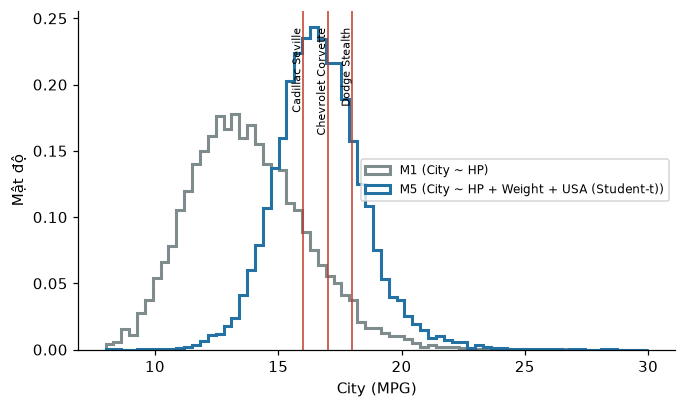

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/figures/fig_5_6_q4_300hp.png


In [39]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(8, 30, 70)
for name, c in zip(dict.fromkeys(["M1", FINAL]), ["#7f8c8d", "#2471a3"]):
    ax.hist(predict_mpg(name, 300, w300, 1)[:, 0], bins=bins, density=True, histtype="step", lw=2,
            color=c, label=f"{name} ({spec[name]['formula']})")
for _, r in real.iterrows():
    ax.axvline(r["city"], c="#c0392b", lw=1)
    ax.text(r["city"], ax.get_ylim()[1] * .95, r["name"], rotation=90, va="top", ha="right", fontsize=7)
ax.set(xlabel="City (MPG)", ylabel="Mật độ",
       title="Hình 5.6 — Phân phối dự đoán hậu nghiệm cho xe Mỹ 300 hp")
ax.legend(fontsize=8, loc="center right")
savefig(fig, "fig_5_6_q4_300hp.png")

In [40]:
save_results(final_model=FINAL, final_note=note,
             compare_loo=cmp_loo[["rank", "elpd_loo", "p_loo", "elpd_diff", "se", "dse", "weight"]].round(3).to_dict("index"),
             compare_waic=cmp_waic[["rank", "elpd_waic", "p_waic", "elpd_diff", "se", "dse"]].round(3).to_dict("index"),
             pareto_k=pareto, ppc_pvalues=ppp.round(3).to_dict("index"),
             q1=q1, q2=q2, q4=q4.round(3).to_dict("records"), q4_real=real_pred.round(3).to_dict("records"),
             q4_weight_kg=w300,
             q3_outliers=outliers[["name", "city", "fitted_mpg", "std_resid", f"pareto_k_{normal_name}"]].to_dict("records"))
print("saved", RESULTS)

saved /Users/huybq/Documents/work stuff/special-topic/final-project/outputs/results.json
